# Case: Atlas Copco (ATCO-A.ST)

Den här notebooken går igenom en hel värdering av Atlas Copco med `valuation-engine`, steg för steg och med motorns publika API. Ordningen är: data, historik, marknadsparametrar, jämförelsebolag (comps), kassaflödesvärdering (DCF), lånefinansierat uppköp (LBO), Monte Carlo, football field och till sist en slutsats.

Allt körs offline mot `tests/fixtures`, så den som klonar repot får exakt samma siffror. Diagrammen sparas samtidigt som PNG i `docs/figures/`, och tabellerna i `docs/case_report.md` skrivs ut i sista avsnittet. Rapporten, notebooken och figurerna kommer alltså från samma körning.

Det här är ett läroexempel och ingen investeringsrådgivning.

## 0. Förberedelser

Kodcellerna är på engelska, texten på svenska. `show()` sparar ett diagram i `docs/figures/` och visar det här. `sv()` formaterar tal med decimalkomma till rapportens tabeller.

In [1]:
import io
import json
import os
from dataclasses import replace
from datetime import date
from decimal import ROUND_HALF_UP, Decimal
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.optimize import brentq

from valuation_engine import data, pipeline, viz
from valuation_engine.models import dcf as dcf_model
from valuation_engine.models import monte_carlo as mc_model
from valuation_engine.viz import style

os.environ["VALUATION_ENGINE_OFFLINE"] = "1"  # fixtures only, never the network

TICKER = "ATCO-A.ST"
BN = 1e9
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
FIG_DIR = ROOT / "docs" / "figures"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.2f}".format


def show(fig, name):
    """Save a chart as docs/figures/<name>.png and display it inline."""
    viz.save_figure(fig, FIG_DIR / name, formats=("png",))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=90, facecolor=style.SURFACE)
    display(Image(data=buffer.getvalue()))


def sv(value, decimals=1, suffix=""):
    """Swedish number format: decimal comma, non-breaking space for thousands.

    Rounds the unrounded value once, half away from zero (192.25 -> 192,3).
    """
    if value is None or not np.isfinite(value):
        return "saknas"
    rounded = Decimal(repr(float(value))).quantize(Decimal(1).scaleb(-decimals), ROUND_HALF_UP)
    text = f"{rounded:,.{decimals}f}".replace(",", "\u00a0").replace(".", ",")
    return text + suffix


def md_table(frame):
    """Print a DataFrame of ready-made strings as a Markdown table."""
    header = [frame.index.name or ""] + [str(column) for column in frame.columns]
    print("| " + " | ".join(header) + " |")
    print("|" + "|".join(["---"] + ["---:"] * len(frame.columns)) + "|")
    for label, row in frame.iterrows():
        print("| " + " | ".join([str(label)] + [str(cell) for cell in row]) + " |")


print("figures are written to", FIG_DIR.relative_to(ROOT).as_posix())

figures are written to docs/figures


## 1. Ladda data

`data.load_company` ger ett `CompanyData` med profil, tre årsrapporter (resultaträkning, balansräkning, kassaflöde), en marknadsbild och fem års veckokurser. Källan är Yahoo Finance, fryst i fixtures.

Lägg märke till att tre olika tidpunkter blandas: kursen är från november 2026, skuld och kassa från kvartalsbokslutet per 30 september 2026, och resultatposterna från räkenskapsåret 2025. Det är en känd svaghet som vi återkommer till.

In [2]:
company = data.load_company(TICKER, offline=True)
profile, market, statements = company.profile, company.market, company.statements
inc, bal, cf = statements.income, statements.balance, statements.cash_flow

overview = pd.Series(
    {
        "name": profile.name,
        "sector / industry": f"{profile.sector} / {profile.industry}",
        "trading / reporting currency": f"{profile.currency} / {profile.reporting_currency}",
        "price (SEK)": market.price,
        "price date": str(market.as_of),
        "shares outstanding, A-share equivalents (bn)": market.shares_outstanding / BN,
        "market cap (SEK bn)": market.market_cap / BN,
        "total debt incl. leases (SEK bn)": market.total_debt / BN,
        "cash (SEK bn)": market.cash / BN,
        "net debt (SEK bn)": market.net_debt / BN,
        "minority interest (SEK bn)": market.minority_interest / BN,
        "enterprise value (SEK bn)": market.enterprise_value / BN,
        "debt and cash taken from": statements.source_map["market.total_debt"].split(":")[0],
        "fiscal years": ", ".join(str(year) for year in statements.fiscal_years),
        "weekly price observations": len(company.price_history.prices),
        "beta according to Yahoo (informational)": market.beta,
    }
)
overview.to_frame("ATCO-A.ST")

,ATCO-A.ST
name,Atlas Copco AB (publ)
sector / industry,Industrials / Specialty Industrial Machinery
trading / reporting currency,SEK / SEK
price (SEK),192.25
price date,2026-11-13
"shares outstanding, A-share equivalents (bn)",4.88
market cap (SEK bn),938.27
total debt incl. leases (SEK bn),37.51
cash (SEK bn),25.11
net debt (SEK bn),12.40


Börsvärdet 938 mdkr gäller hela bolaget (A- och B-aktier), men alla aktier räknas till A-aktiens kurs. Därför är antalet aktier här `market_cap / price`, inte det antal A-aktier som faktiskt finns. Nettoskulden är liten jämfört med börsvärdet: 12,4 mdkr mot 938 mdkr.

## 2. Historiska rapporter

Fyra räkenskapsår är allt Yahoo ger. Beloppen nedan är i miljarder kronor. Kostnader, capex och avskrivningar är lagrade som positiva tal.

In [3]:
(inc.drop(columns="diluted_shares") / BN).T

fiscal_year,2022,2023,2024,2025
revenue,141.32,172.66,176.77,168.34
cogs,81.94,97.55,101.03,96.13
gross_profit,59.38,75.12,75.74,72.21
ebitda,36.82,45.12,47.50,44.08
depreciation_amortization,6.33,7.76,8.79,9.53
ebit,30.48,37.36,38.72,34.55
interest_expense,0.44,0.91,0.92,0.88
pretax_income,30.04,36.44,37.80,33.67
income_tax,6.56,8.39,8.01,7.25
net_income,23.48,28.04,29.78,26.42


In [4]:
(bal / BN).T

fiscal_year,2022,2023,2024,2025
cash,11.85,11.22,19.33,15.92
accounts_receivable,29.91,32.68,33.82,29.89
inventory,27.22,29.28,29.01,26.66
accounts_payable,19.14,17.79,16.79,16.39
total_current_assets,80.21,86.21,95.51,87.02
total_current_liabilities,61.46,54.21,55.41,56.01
net_ppe,20.16,24.47,30.82,33.51
goodwill_intangibles,67.07,67.50,77.11,77.08
total_assets,172.30,182.68,208.54,202.45
total_debt,36.30,32.59,34.71,34.83


In [5]:
(cf / BN).T

fiscal_year,2022,2023,2024,2025
cash_from_operations,21.38,28.08,36.89,32.57
depreciation_amortization,6.33,7.76,8.79,9.53
change_in_nwc,7.42,5.78,-2.07,-1.62
capex,5.03,5.45,6.02,6.19
dividends_paid,9.25,11.20,13.65,14.61
free_cash_flow,16.35,22.63,30.86,26.38


### Nyckeltal ur historiken

Motorns standardantaganden byggs av de här kvoterna, så det är dem vi ska granska. Utöver motorns egna poster hämtar vi några råa Yahoo-rader ur fixturefilen som motorn inte använder men som hjälper oss att bedöma antagandena: förvärv, avskrivningar på immateriella tillgångar, leasingskulder och kortfristiga lån.

In [6]:
raw = json.loads((data.fixtures_dir() / "companies" / f"{TICKER}.json").read_text(encoding="utf-8"))


def raw_rows(statement, names):
    """Raw Yahoo rows of the fixture file, indexed by fiscal year (SEK)."""
    block = raw["statements"][statement]
    years = [int(period[:4]) for period in block["periods"]]
    frame = pd.DataFrame(
        {name: pd.Series(block["rows"][name], index=years, dtype=float) for name in names}
    )
    return frame.sort_index().loc[statements.fiscal_years]


raw_cf = raw_rows("cashflow", ["Purchase Of Business", "Amortization Cash Flow"]).abs()
raw_bs = raw_rows(
    "balance_sheet",
    [
        "Capital Lease Obligations",
        "Current Capital Lease Obligation",
        "Current Debt And Capital Lease Obligation",
    ],
)

# Broad working capital: non-cash current assets less non-debt current liabilities.
broad_nwc = (bal["total_current_assets"] - bal["cash"]) - (
    bal["total_current_liabilities"] - raw_bs["Current Debt And Capital Lease Obligation"]
)

ratios = pd.DataFrame(
    {
        "revenue growth": inc["revenue"].pct_change(),
        "EBITDA margin": inc["ebitda"] / inc["revenue"],
        "EBIT margin": inc["ebit"] / inc["revenue"],
        "D&A / revenue": inc["depreciation_amortization"] / inc["revenue"],
        "capex / revenue": cf["capex"] / inc["revenue"],
        "operating NWC / revenue (engine: AR + inventory - AP)": bal["net_working_capital"]
        / inc["revenue"],
        "broad NWC / revenue (non-cash CA - non-debt CL)": broad_nwc / inc["revenue"],
        "effective tax rate": inc["income_tax"] / inc["pretax_income"],
        "free cash flow / revenue": cf["free_cash_flow"] / inc["revenue"],
        "acquisitions / revenue (raw row, not used by the engine)": raw_cf["Purchase Of Business"]
        / inc["revenue"],
    }
)
(ratios * 100).round(1).T

,2022,2023,2024,2025
revenue growth,NaN,22.20,2.40,-4.80
EBITDA margin,26.10,26.10,26.90,26.20
EBIT margin,21.60,21.60,21.90,20.50
D&A / revenue,4.50,4.50,5.00,5.70
capex / revenue,3.60,3.20,3.40,3.70
operating NWC / revenue (engine: AR + inventory - AP),26.90,25.60,26.00,23.90
broad NWC / revenue (non-cash CA - non-debt CL),13.80,13.60,13.50,12.80
effective tax rate,21.80,23.00,21.20,21.50
free cash flow / revenue,11.60,13.10,17.50,15.70
"acquisitions / revenue (raw row, not used by the engine)",7.50,2.50,4.20,6.90


In [7]:
supplement = pd.DataFrame(
    {
        "acquisitions (Purchase Of Business)": raw_cf["Purchase Of Business"],
        "amortization of intangibles": raw_cf["Amortization Cash Flow"],
        "total D&A": inc["depreciation_amortization"],
        "capex (PPE + intangibles)": cf["capex"],
        "lease liabilities (in total debt)": raw_bs["Capital Lease Obligations"],
        "current lease liabilities": raw_bs["Current Capital Lease Obligation"],
        "broad NWC": broad_nwc,
        "operating NWC (engine)": bal["net_working_capital"],
    }
)
(supplement / BN).T

,2022,2023,2024,2025
acquisitions (Purchase Of Business),10.59,4.31,7.42,11.56
amortization of intangibles,2.68,3.30,3.61,3.83
total D&A,6.33,7.76,8.79,9.53
capex (PPE + intangibles),5.03,5.45,6.02,6.19
lease liabilities (in total debt),4.82,5.74,7.15,7.38
current lease liabilities,1.31,1.49,1.76,1.77
broad NWC,19.47,23.52,23.84,21.56
operating NWC (engine),37.98,44.17,46.04,40.16


In [8]:
# Yahoo's trailing-twelve-month figures (info block of the fixture; not used by the engine).
info = raw["info"]
ttm = (
    pd.DataFrame(
        {
            "FY2025 (used by the engine)": [
                inc["revenue"].iloc[-1],
                inc["ebitda"].iloc[-1],
                inc["net_income"].iloc[-1],
            ],
            "trailing twelve months (Yahoo info)": [
                info["totalRevenue"],
                info["ebitda"],
                info["netIncomeToCommon"],
            ],
        },
        index=["revenue", "EBITDA", "net income"],
    )
    / BN
)
ttm["change (%)"] = (ttm.iloc[:, 1] / ttm.iloc[:, 0] - 1) * 100
ttm

,FY2025 (used by the engine),trailing twelve months (Yahoo info),change (%)
revenue,168.34,176.22,4.68
EBITDA,44.08,43.90,-0.42
net income,26.42,27.66,4.69


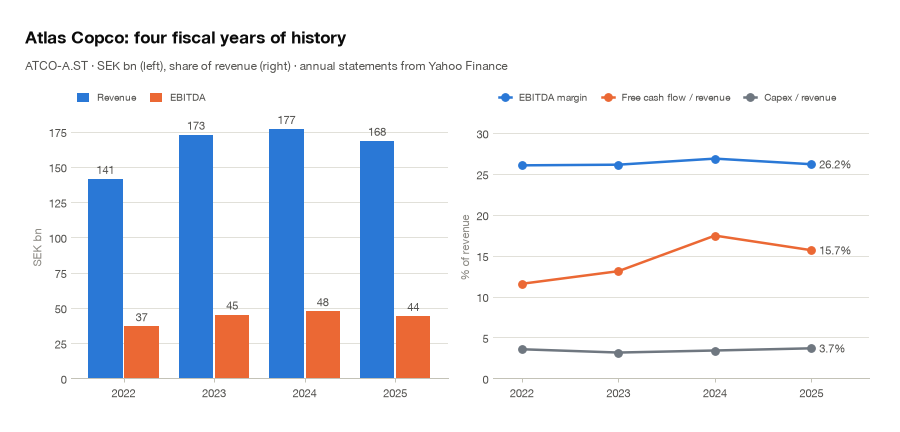

In [9]:
years = statements.fiscal_years
x = np.arange(len(years))
fig, (left, right) = style.new_figure(
    "Atlas Copco: four fiscal years of history",
    "ATCO-A.ST · SEK bn (left), share of revenue (right) · annual statements from Yahoo Finance",
    figsize=(10.0, 4.8),
    ncols=2,
)
for offset, column, colour, label in (
    (-0.2, "revenue", style.BLUE, "Revenue"),
    (0.2, "ebitda", style.ORANGE, "EBITDA"),
):
    values = inc[column].to_numpy() / BN
    left.bar(x + offset, values, width=0.38, color=colour, label=label)
    for position, value in zip(x + offset, values, strict=True):
        left.text(
            position,
            value + 2,
            f"{value:.0f}",
            ha="center",
            va="bottom",
            fontsize=9,
            color=style.SECONDARY,
        )
left.set_xticks(x, [str(year) for year in years])
left.set_ylabel("SEK bn")
style.style_legend(left, loc="upper left", ncols=2, bbox_to_anchor=(0.0, 1.12))

for column, colour, label in (
    ("EBITDA margin", style.BLUE, "EBITDA margin"),
    ("free cash flow / revenue", style.ORANGE, "Free cash flow / revenue"),
    ("capex / revenue", style.NEUTRAL, "Capex / revenue"),
):
    values = ratios[column].to_numpy() * 100
    right.plot(x, values, marker="o", color=colour, linewidth=2, label=label)
    right.text(
        x[-1] + 0.08,
        values[-1],
        f"{values[-1]:.1f}%",
        va="center",
        fontsize=9,
        color=style.SECONDARY,
    )
right.set_xticks(x, [str(year) for year in years])
right.set_xlim(-0.3, len(years) - 0.4)
right.set_ylim(0, 32)
right.set_ylabel("% of revenue")
style.style_legend(right, loc="upper left", ncols=3, bbox_to_anchor=(0.0, 1.12))
show(style.finalize(fig), "history_overview")

Vad historiken säger, kort:

* **Tillväxten är ojämn.** Omsättningen steg 22 % under 2023 och har sedan stått ungefär still (+2 % 2024, minus 5 % 2025). Treårssnittet på 6,0 % per år vilar alltså nästan helt på ett enda år.
* **Marginalerna är stabila.** EBITDA-marginalen ligger mellan 26,1 och 26,9 % alla fyra åren.
* **Avskrivningarna växer snabbare än omsättningen**, från 4,5 till 5,7 % av omsättningen. En stor del är avskrivningar på förvärvade immateriella tillgångar (3,8 av 9,5 mdkr 2025).
* **Bolaget köper tillväxt.** Förvärven har kostat mellan 4 och 12 mdkr per år. De syns i omsättningen men inte i capex, och det spelar roll för DCF:en längre ned.
* **Rörelsekapitalet beror på hur man mäter.** Motorns smala mått (kundfordringar plus lager minus leverantörsskulder) är runt 25 % av omsättningen. Räknar man med övriga rörelseskulder (förskott, upplupna kostnader med mera) blir det runt 13 %.
* **Skatten är högre än den svenska skattesatsen.** Den effektiva skatten har legat mellan 21,2 och 23,0 %, mot lagstadgade 20,6 %.
* **2025 är ett svagt basår.** Yahoos rullande tolvmånaderssiffror (som motorn inte använder) visar en omsättning 4,7 % över helåret 2025.

## 3. Marknadsparametrar och deras källor

Fyra tal som gäller hela marknaden styr avkastningskravet. Motorn sparar varifrån vart och ett kommer. Två är hämtade från en namngiven källa med datum (riskfri ränta från Riksbanken, riskpremie och skattesats från Damodaran). Två är projektets egna val: jämförelseindex och den långsiktiga tillväxten på 2 %, som är Riksbankens inflationsmål använt som nominellt ankare.

In [10]:
sources = data.market_parameter_sources(offline=True)
pd.DataFrame(
    [
        {
            "parameter": name,
            "value": source.value if isinstance(source.value, str) else f"{source.value:.3%}",
            "origin": source.origin,
            "as of": source.as_of or "",
            "source": source.source,
        }
        for name, source in sources.items()
    ]
).set_index("parameter")

,value,origin,as of,source
parameter,,,,
risk_free_rate,3.075%,fixtures,2026-11-13,"Sveriges Riksbank, Swedish 10-year government ..."
equity_risk_premium,4.230%,reference file,2026-01-01,"Damodaran, Country Default Spreads and Risk Pr..."
tax_rate,20.600%,reference file,2026-01-01,"Damodaran, Country Default Spreads and Risk Pr..."
benchmark,^OMXSPI,default,,OMX Stockholm PI on Yahoo Finance (project def...
long_term_growth,2.000%,default,,Riksbank inflation target of 2 % as nominal an...
country_risk_premium,0.000%,reference file,2026-01-01,"Damodaran, Country Default Spreads and Risk Pr..."


## 4. Kör hela värderingen

`pipeline.run_valuation` kör modellerna i en bestämd ordning: först comps (som väljer jämförelsebolag), sedan DCF på samma jämförelsebolag (för beta och exit-multipel), sedan LBO med DCF:ens exit-multipel och sist Monte Carlo runt DCF:ens basfall. Här används motorns standardantaganden rakt av, 10 000 simuleringar och frö 42.

Resten av notebooken öppnar resultatet del för del.

In [11]:
report = pipeline.run_valuation(TICKER, offline=True)
charts = viz.build_charts(report)
price = report.price
print(pipeline.summary_text(report))

Atlas Copco AB (publ) (ATCO-A.ST)
Industrials, Specialty Industrial Machinery, market data as of 2026-11-13
Price SEK 192.25 | market cap SEK 938.3 bn | EV SEK 950.9 bn | net debt SEK 12.4 bn | FY2025
----------------------------------------------------------------------------------------------------
Value per share (SEK)
Method                                 Low        Base        High  Base/price   vs. price
Comps - EV/EBITDA                   152.81      172.93      190.71       0.90x      -10.1%
Comps - EV/Sales                    111.67      138.62      168.80       0.72x      -27.9%
Comps - P/E                         162.82      178.33      196.54       0.93x       -7.2%
DCF - Gordon growth                  93.73      115.85      153.74       0.60x      -39.7%
DCF - Exit multiple                 160.55      175.23      191.04       0.91x       -8.9%
LBO - ability to pay                104.38      117.93      135.34       0.61x      -38.7%
Monte Carlo DCF (P10 - P90)          84

## 5. Comps: jämförelsebolag och multiplar

Idén med comps är enkel: liknande bolag borde värderas till liknande multiplar. Det svåra är ordet "liknande". Motorn gör så här:

1. Kandidaterna är alla bolag i samma Yahoo-sektor (Industrials) som har börsvärde och minst en användbar multipel.
2. Varje bolag beskrivs med sex tal: log börsvärde, omsättningstillväxt, EBITDA-marginal, avkastning på eget kapital, beta och skuldsättning. Talen kapas, winsoriseras och standardiseras till z-värden.
3. K-means körs för k = 2 till 8, och det k som ger högst silhuettvärde vinner.
4. Jämförelsebolagen är de bolag i Atlas Copcos kluster som ligger närmast i z-rummet, med ett straff på 0,5 för annan bransch. Högst 12 bolag väljs.

In [12]:
comps = report.comps
print("candidate scope:", comps.candidate_scope, "| candidates:", len(comps.candidates))
print("features:", ", ".join(comps.feature_names))
print("chosen k:", comps.chosen_k, "| fallbacks:", ", ".join(comps.fallbacks))
print(
    "cluster sizes:",
    comps.candidates["cluster"].value_counts().to_dict(),
    "| target cluster:",
    comps.target_cluster,
)
pd.Series(comps.silhouette_scores, name="silhouette score").rename_axis("k").to_frame().T

candidate scope: sector | candidates: 148
features: log_market_cap, revenue_growth, ebitda_margin, return_on_equity, beta, leverage
chosen k: 2 | fallbacks: cluster_capped_to_nearest, multiple_outliers_removed:ev_ebitda, multiple_outliers_removed:ev_sales, multiple_outliers_removed:pe
cluster sizes: {0: 119, 1: 29} | target cluster: 0


k,2,3,4,5,6,7,8
silhouette score,0.38,0.28,0.29,0.31,0.32,0.32,0.28


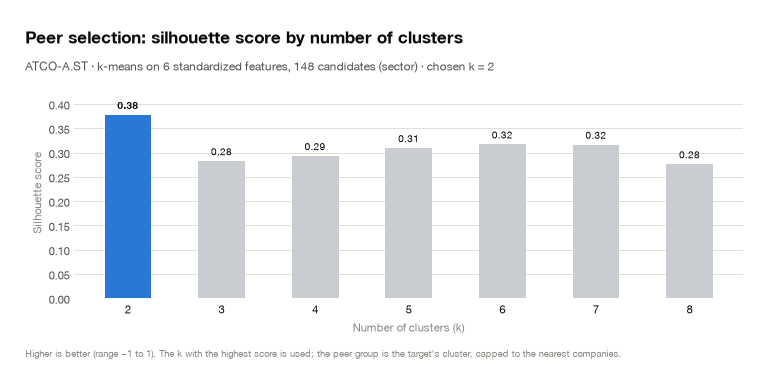

In [13]:
show(charts["comps_silhouette"], "comps_silhouette")

Silhuettvärdet är högst för k = 2, men 0,38 är inget starkt klusterbevis. Viktigare är klustrens storlek: 119 av 148 kandidater hamnar i samma kluster som Atlas Copco. Klustringen sorterar alltså bara bort en grupp på 29 avvikande bolag. Det verkliga urvalet görs av steg 4: de tolv närmaste grannarna, med förtur för samma bransch. Det är bra att veta när man läser "k-means-urval" i beskrivningen.

Så här ser Atlas Copco ut i de sex dimensionerna (z-värden mätt mot kandidaterna):

In [14]:
comps.target_features.T

feature,log_market_cap,revenue_growth,ebitda_margin,return_on_equity,beta,leverage
raw,11.97,-0.05,0.26,0.24,1.26,0.04
z,1.82,-0.47,0.91,0.98,1.43,-1.00


In [15]:
peer_columns = [
    "name",
    "industry",
    "ranking_distance",
    "market_cap",
    "revenue_growth",
    "ebitda_margin",
    "return_on_equity",
    "beta",
    "ev_ebitda",
    "ev_sales",
    "pe",
    "used_ev_ebitda",
]
peers = comps.peers[peer_columns].copy()
peers["market_cap"] = peers["market_cap"] / BN
peers = peers.rename(columns={"market_cap": "market_cap_bn", "used_ev_ebitda": "used"})
peers

,name,industry,ranking_distance,market_cap_bn,revenue_growth,ebitda_margin,return_on_equity,beta,ev_ebitda,ev_sales,pe,used
ticker,,,,,,,,,,,,
SAND.ST,Sandvik AB (publ),Specialty Industrial Machinery,0.46,454.21,-0.02,0.24,0.15,1.29,17.21,4.09,30.92,True
ALFA.ST,Alfa Laval AB (publ),Specialty Industrial Machinery,0.75,226.50,0.04,0.20,0.19,1.05,16.90,3.46,27.38,True
EPI-A.ST,Epiroc AB (publ),Farm & Heavy Construction Machinery,0.77,295.53,-0.03,0.24,0.20,1.19,20.16,4.92,34.36,True
TREL-B.ST,Trelleborg AB (publ),Specialty Industrial Machinery,0.98,104.12,0.00,0.21,0.09,1.04,15.64,3.30,28.95,True
MYCR.ST,Mycronic AB (publ),Specialty Industrial Machinery,1.09,56.63,0.12,0.29,0.23,1.01,23.21,6.77,36.30,True
LIFCO-B.ST,Lifco AB (publ),Conglomerates,1.10,131.90,0.08,0.25,0.19,1.30,20.18,5.01,36.31,True
ADDT-B.ST,Addtech AB (publ.),Industrial Distribution,1.23,89.72,0.04,0.18,0.30,1.39,23.55,4.25,41.79,True
INDT.ST,Indutrade AB (publ),Industrial Distribution,1.27,97.57,-0.01,0.17,0.15,1.44,19.43,3.32,38.11,True
EPRO-B.ST,Electrolux Professional AB (publ),Specialty Industrial Machinery,1.37,15.49,-0.03,0.14,0.13,1.19,10.51,1.43,21.05,False


Tre saker syns i tabellen:

* Alla jämförelsebolag är mindre än Atlas Copco. Det största, Sandvik, har ungefär halva börsvärdet. Atlas Copco är näst störst i sektorn efter ABB (se nästa cell), så det finns få jämnstora att välja bland. ABB och Volvo valdes inte: de ligger i andra branscher och längre bort i z-rummet.
* Gruppen är blandad. Sandvik, Alfa Laval, Epiroc och Trelleborg är verkstadsbolag av liknande slag. Addtech och Indutrade är teknikhandel, Lifco och Latour är konglomerat (Latour är dessutom ett investmentbolag som Yahoo lägger i Industrials).
* Electrolux Professional har klart lägst multiplar och tas bort som uteliggare (Tukey-staket på logaritmerade multiplar) i alla tre multiplarna. Kvar blir 11 observationer. DCF:ens exit-multipel är samma median av samma 11 bolag.

In [16]:
# The largest companies of the sector in the peer universe, and whether they were selected.
universe_peers = data.load_peer_snapshots(offline=True)
largest = sorted(
    (p for p in universe_peers if p.sector == profile.sector),
    key=lambda p: p.market_cap,
    reverse=True,
)[:6]
pd.DataFrame(
    {
        p.ticker: {
            "industry": p.industry,
            "market_cap_bn": p.market_cap / BN,
            "ebitda_margin": p.ebitda_margin,
            "ev_ebitda": p.ev_ebitda,
            "selected as peer": p.ticker in comps.peer_tickers,
        }
        for p in largest
    }
).T

,industry,market_cap_bn,ebitda_margin,ev_ebitda,selected as peer
ABB.ST,Electrical Equipment & Parts,"1,525.15",0.21,22.20,False
ATCO-A.ST,Specialty Industrial Machinery,938.27,0.26,21.57,False
VOLV-B.ST,Farm & Heavy Construction Machinery,657.82,0.15,12.26,False
SAND.ST,Specialty Industrial Machinery,454.21,0.24,17.21,True
ASSA-B.ST,Security & Protection Services,439.53,0.19,17.19,True
SAAB-B.ST,Aerospace & Defense,335.56,0.15,28.52,False


In [17]:
summary = comps.multiples_summary.copy()
summary["target (ATCO at market)"] = pd.Series(comps.target_multiples)
summary["target vs. median"] = summary["target (ATCO at market)"] / summary["median"] - 1
summary

,n,min,p25,median,mean,p75,max,target (ATCO at market),target vs. median
multiple,,,,,,,,,
ev_ebitda,11.00,15.64,17.20,19.43,19.45,21.40,23.55,21.57,0.11
ev_sales,11.00,2.77,3.31,4.09,4.27,4.97,6.77,5.65,0.38
pe,11.00,27.38,30.08,32.94,33.38,36.31,41.79,35.51,0.08


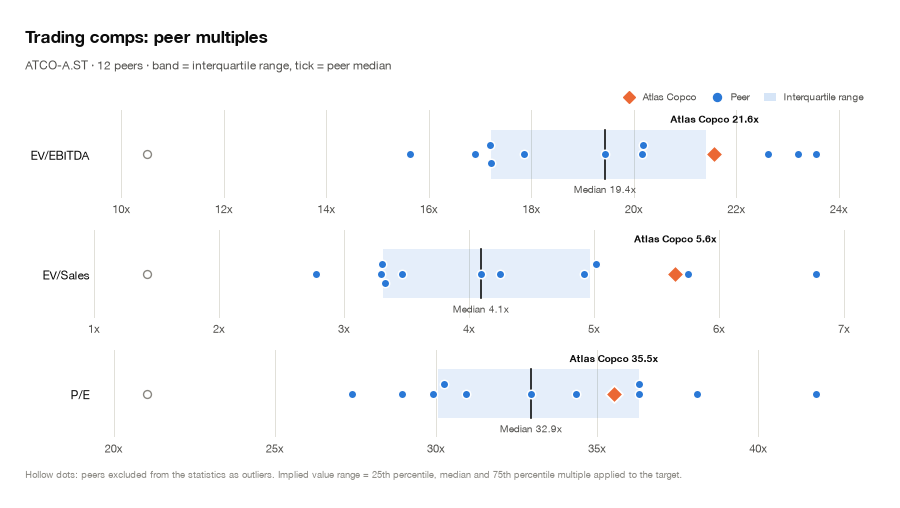

In [18]:
show(charts["comps_peer_multiples"], "comps_peer_multiples")

Det implicita värdet är peer-multipeln gånger Atlas Copcos eget mått: 25:e percentilen ger lågt värde, medianen basvärde och 75:e percentilen högt värde. För EV-multiplarna dras nettoskuld och minoritet av innan man delar med antalet aktier.

In [19]:
implied = comps.implied_values[
    [
        "metric",
        "n_peers",
        "multiple_low",
        "multiple_base",
        "multiple_high",
        "per_share_low",
        "per_share_base",
        "per_share_high",
        "base_to_price",
    ]
]
peer_median_margin = comps.peers.loc[comps.peers["used_ev_sales"], "ebitda_margin"].median()
own_margin = inc["ebitda"].iloc[-1] / inc["revenue"].iloc[-1]
print(f"EBITDA margin: ATCO {own_margin:.1%}, median of the peers used {peer_median_margin:.1%}")
implied

EBITDA margin: ATCO 26.2%, median of the peers used 21.1%


,metric,n_peers,multiple_low,multiple_base,multiple_high,per_share_low,per_share_base,per_share_high,base_to_price
multiple,,,,,,,,,
ev_ebitda,ebitda,11,17.20,19.43,21.40,152.81,172.93,190.71,0.90
ev_sales,revenue,11,3.31,4.09,4.97,111.67,138.62,168.80,0.72
pe,net_income,11,30.08,32.94,36.31,162.82,178.33,196.54,0.93


Atlas Copco handlas till 21,6 gånger EBITDA och 35,5 gånger vinsten. Det är 11 % respektive 8 % över peer-medianen men ungefär i nivå med 75:e percentilen. Bolaget är alltså inte udda prissatt jämfört med gruppen. EV/Sales ger ett klart lägre värde, och det beror på metoden: en omsättningsmultipel tar ingen hänsyn till att Atlas Copcos marginal (26,2 %) är högre än gruppens median (21,1 %).

## 6. DCF: diskonterade kassaflöden

En DCF värderar bolaget som summan av alla framtida fria kassaflöden, diskonterade till i dag med avkastningskravet WACC. Motorn prognostiserar fem år och lägger sedan till ett slutvärde (terminal value) för allt därefter.

### 6.1 Antaganden

Standardantagandena räknas mekaniskt ur historiken. Tabellen ställer dem bredvid de historiska talen.

In [20]:
dcf = report.dcf
a = dcf.assumptions
window = ratios.iloc[-dcf_model.HISTORY_WINDOW :]
cagr = (inc["revenue"].iloc[-1] / inc["revenue"].iloc[0]) ** (1 / (len(inc) - 1)) - 1
assumption_table = pd.DataFrame(
    {
        "engine default": [
            " -> ".join(f"{g:.1%}" for g in a.revenue_growth),
            f"{a.ebitda_margin[0]:.1%} flat",
            f"{a.da_pct_revenue:.2%}",
            f"{a.capex_pct_revenue:.2%} (terminal year: max(capex, D&A))",
            f"{a.nwc_pct_revenue:.1%}",
            f"{a.tax_rate:.1%}",
            f"{a.terminal_growth:.1%}",
            f"{a.wacc:.2%}",
            f"{a.exit_multiple:.1f}x",
        ],
        "history": [
            f"CAGR 2022-2025 {cagr:.1%}; yearly "
            + ", ".join(f"{g:+.1%}" for g in ratios["revenue growth"].dropna()),
            f"3y mean {window['EBITDA margin'].mean():.1%}; FY2025 {own_margin:.1%}",
            f"3y mean {window['D&A / revenue'].mean():.2%}; "
            f"FY2025 {ratios['D&A / revenue'].iloc[-1]:.2%}",
            f"3y mean {window['capex / revenue'].mean():.2%}; "
            f"FY2025 {ratios['capex / revenue'].iloc[-1]:.2%}",
            f"3y mean {window.iloc[:, 5].mean():.1%} (narrow), "
            f"{window.iloc[:, 6].mean():.1%} (broad)",
            f"effective 3y mean {window['effective tax rate'].mean():.1%}",
            "not from history: 2 % inflation target",
            "not from history: CAPM, see below",
            f"ATCO at market {comps.target_multiples['ev_ebitda']:.1f}x",
        ],
        "rule": [
            "historical CAGR (clipped to -5%..15%), linear fade to 2% in year 5",
            "mean of the last 3 years, held flat",
            "mean of the last 3 years",
            "mean of the last 3 years",
            "mean of the last 3 years of (AR + inventory - AP) / revenue",
            "statutory rate from the market parameters",
            "long-term growth from the market parameters",
            "CAPM with own and peer beta",
            "comps EV/EBITDA median after the outlier fence (11 peers)",
        ],
    },
    index=[
        "revenue growth, years 1-5",
        "EBITDA margin",
        "D&A / revenue",
        "capex / revenue",
        "NWC / revenue",
        "tax rate",
        "terminal growth",
        "WACC",
        "exit multiple",
    ],
)
with pd.option_context("display.max_colwidth", None):
    display(assumption_table)
print("notes from the engine:", dcf.notes or "none")

,engine default,history,rule
"revenue growth, years 1-5",6.0% -> 5.0% -> 4.0% -> 3.0% -> 2.0%,"CAGR 2022-2025 6.0%; yearly +22.2%, +2.4%, -4.8%","historical CAGR (clipped to -5%..15%), linear fade to 2% in year 5"
EBITDA margin,26.4% flat,3y mean 26.4%; FY2025 26.2%,"mean of the last 3 years, held flat"
D&A / revenue,5.04%,3y mean 5.04%; FY2025 5.66%,mean of the last 3 years
capex / revenue,"3.41% (terminal year: max(capex, D&A))",3y mean 3.41%; FY2025 3.68%,mean of the last 3 years
NWC / revenue,25.2%,"3y mean 25.2% (narrow), 13.3% (broad)",mean of the last 3 years of (AR + inventory - AP) / revenue
tax rate,20.6%,effective 3y mean 21.9%,statutory rate from the market parameters
terminal growth,2.0%,not from history: 2 % inflation target,long-term growth from the market parameters
WACC,7.65%,"not from history: CAPM, see below",CAPM with own and peer beta
exit multiple,19.4x,ATCO at market 21.6x,comps EV/EBITDA median after the outlier fence (11 peers)


notes from the engine: none


### 6.2 WACC steg för steg

WACC är ett vägt snitt av vad aktieägare och långivare kräver i avkastning. Aktieägarnas krav kommer från CAPM: riskfri ränta plus beta gånger marknadens riskpremie. Beta mäter hur mycket aktien rör sig med börsen.

Motorn tar snittet av två betan: bolagets eget (regression på 260 veckors avkastning mot OMXSPI, Blume-justerat mot 1) och jämförelsebolagens (rensat från skuldsättning, medianen, åter belånat med Atlas Copcos skuldsättning, Blume-justerat).

In [21]:
w = dcf.wacc_result
wacc_table = pd.Series(
    {
        "risk-free rate (Riksbank 10y)": w.risk_free_rate,
        "equity risk premium (Damodaran)": w.equity_risk_premium,
        "own raw beta (260 weekly returns vs. ^OMXSPI)": w.raw_beta,
        "  R squared of the regression": w.raw_beta_r_squared,
        "own beta, Blume-adjusted (2/3 x raw + 1/3)": w.blume_beta,
        f"peer unlevered beta (median of {w.peer_count} peers)": w.peer_unlevered_beta,
        "peer beta relevered at ATCO's D/E": w.peer_relevered_beta,
        "peer beta, Blume-adjusted": w.peer_beta,
        "beta used (average of own and peer)": w.beta,
        "size premium (market cap above SEK 20 bn)": w.size_premium,
        "cost of equity = rf + beta x ERP + size premium": w.cost_of_equity,
        "pre-tax cost of debt": w.pre_tax_cost_of_debt,
        "after-tax cost of debt": w.after_tax_cost_of_debt,
        "debt / equity (market values)": w.debt_to_equity,
        "equity weight": w.equity_weight,
        "debt weight": w.debt_weight,
        "WACC": w.wacc,
    }
)
print("beta method:", w.beta_method)
print("cost of debt:", w.cost_of_debt_source)
by_hand = w.equity_weight * (
    w.risk_free_rate + w.beta * w.equity_risk_premium + w.size_premium
) + w.debt_weight * w.pre_tax_cost_of_debt * (1 - w.tax_rate)
print(f"WACC recomputed by hand: {by_hand:.4%}")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(wacc_table.to_frame("value"))

beta method: average of own Blume-adjusted beta and relevered peer beta
cost of debt: interest expense / average total debt (2.5%, clipped to 3.6%..9.1%)
WACC recomputed by hand: 7.6520%


,value
risk-free rate (Riksbank 10y),0.0307
equity risk premium (Damodaran),0.0423
own raw beta (260 weekly returns vs. ^OMXSPI),1.2565
R squared of the regression,0.6014
"own beta, Blume-adjusted (2/3 x raw + 1/3)",1.1710
peer unlevered beta (median of 12 peers),1.0914
peer beta relevered at ATCO's D/E,1.1260
"peer beta, Blume-adjusted",1.0840
beta used (average of own and peer),1.1275
size premium (market cap above SEK 20 bn),0.0000


Eftersom Atlas Copco nästan saknar nettoskuld är 96 % av kapitalet eget kapital, och WACC (7,65 %) hamnar strax under avkastningskravet på eget kapital (7,84 %). Skuldräntan spelar nästan ingen roll här. Den beräknade räntan (räntekostnad delat med skuld, 2,5 %) låg under golvet riskfri ränta plus 0,5 procentenheter och har därför kapats till 3,6 %.

### 6.3 Prognosen

Fritt kassaflöde till alla finansiärer (FCFF) är rörelseresultat efter skatt (NOPAT) plus avskrivningar, minus investeringar och minus ökningen av rörelsekapitalet. Med mittårskonventionen antas varje års kassaflöde komma mitt i året, så år 1 diskonteras 0,5 år, år 2 1,5 år och så vidare.

In [22]:
forecast = dcf.forecast.copy()
money = [
    c
    for c in forecast.columns
    if c not in ("revenue_growth", "ebitda_margin", "discount_period", "discount_factor")
]
forecast[money] = forecast[money] / BN
with pd.option_context("display.float_format", "{:.3f}".format):
    display(forecast.T)

fiscal_year,2026,2027,2028,2029,2030
revenue,178.452,187.381,194.880,200.729,204.744
revenue_growth,0.060,0.050,0.040,0.030,0.020
ebitda,47.104,49.461,51.441,52.985,54.044
ebitda_margin,0.264,0.264,0.264,0.264,0.264
depreciation_amortization,8.997,9.447,9.825,10.120,10.323
ebit,38.107,40.014,41.616,42.865,43.722
taxes,7.850,8.243,8.573,8.830,9.007
nopat,30.257,31.771,33.043,34.034,34.715
capex,6.091,6.396,6.652,6.852,6.989
delta_nwc,2.543,2.247,1.887,1.472,1.010


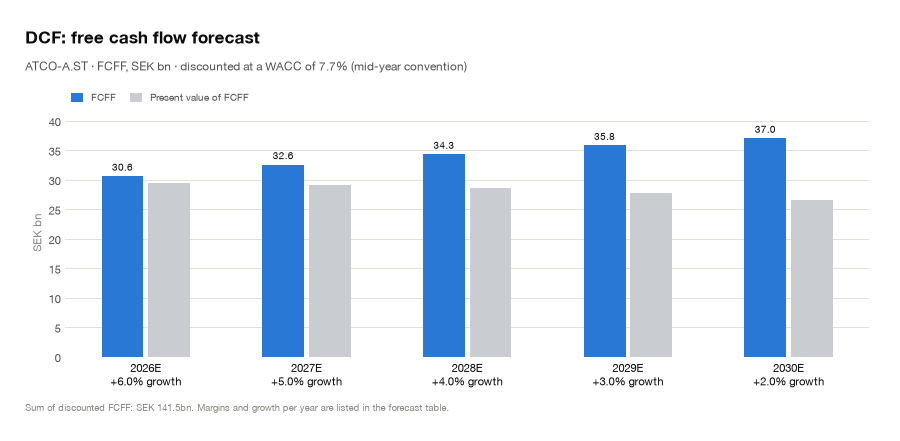

In [23]:
show(charts["dcf_fcff_forecast"], "dcf_fcff_forecast")

### 6.4 Två slutvärden

Slutvärdet räknas på två sätt, och skillnaden mellan dem är hela poängen med det här caset.

* **Gordon-tillväxt.** Kassaflödet antas växa med g = 2 % för alltid. Värdet vid slutet av år 5 är `FCFF_6 / (WACC - g)`, gånger en halvårsfaktor för mittårskonventionen. I det normaliserade år 6 sätts capex minst lika högt som avskrivningarna, annars skulle tillgångarna krympa för evigt medan omsättningen växer.
* **Exit-multipel.** Bolaget antas säljas i slutet av år 5 till jämförelsebolagens EV/EBITDA-multipel i dag (19,4x, medianen från comps).

In [24]:
last = dcf.forecast.iloc[-1]
tv_by_hand = dcf.terminal_fcff / (dcf.wacc - a.terminal_growth) * (1 + dcf.wacc) ** 0.5
terminal = pd.DataFrame(
    {
        "Gordon growth": [
            dcf.terminal_fcff / BN,
            dcf.terminal_value_gordon / BN,
            dcf.pv_terminal_value_gordon / BN,
            dcf.pv_fcff / BN,
            dcf.enterprise_value_gordon / BN,
            dcf.tv_share_gordon * 100,
            dcf.terminal_value_gordon / last["ebitda"],
            a.terminal_growth * 100,
        ],
        "Exit multiple": [
            np.nan,
            dcf.terminal_value_exit / BN,
            dcf.pv_terminal_value_exit / BN,
            dcf.pv_fcff / BN,
            dcf.enterprise_value_exit / BN,
            dcf.tv_share_exit * 100,
            dcf.exit_multiple,
            dcf.implied_perpetual_growth * 100,
        ],
    },
    index=[
        "normalized FCFF year 6 (SEK bn)",
        "terminal value at end of year 5 (SEK bn)",
        "PV of terminal value (SEK bn)",
        "PV of FCFF years 1-5 (SEK bn)",
        "enterprise value (SEK bn)",
        "terminal value share of EV (%)",
        "terminal value / EBITDA year 5 (x)",
        "perpetual growth, assumed or implied (%)",
    ],
)
print(f"Gordon terminal value recomputed by hand: {tv_by_hand / BN:,.1f} bn")
print("exit multiple source:", dcf.exit_multiple_source)
terminal

Gordon terminal value recomputed by hand: 631.1 bn
exit multiple source: comps median EV/EBITDA (11 peers)


,Gordon growth,Exit multiple
normalized FCFF year 6 (SEK bn),34.38,NaN
terminal value at end of year 5 (SEK bn),631.11,"1,050.17"
PV of terminal value (SEK bn),436.51,726.35
PV of FCFF years 1-5 (SEK bn),141.49,141.49
enterprise value (SEK bn),578.00,867.84
terminal value share of EV (%),75.52,83.70
terminal value / EBITDA year 5 (x),11.68,19.43
"perpetual growth, assumed or implied (%)",2.00,4.29


Här ligger kärnan. Gordon-värdet motsvarar att bolaget säljs för 11,7 gånger EBITDA om fem år. Exit-metoden antar 19,4 gånger. Omvänt: för att Gordon-formeln ska ge samma slutvärde som exit-multipeln måste kassaflödet växa med 4,3 % per år för alltid, inte 2 %. De två metoderna beskriver alltså två olika världar, och i båda står slutvärdet för 76 till 84 % av hela värdet.

### 6.5 Från rörelsevärde till värde per aktie

Rörelsevärdet (EV) tillhör alla finansiärer. Aktieägarnas del är det som blir kvar när nettoskuld och minoritetsintressen dragits av.

In [25]:
bridge = dcf.bridge()
bridge.loc[bridge.index.difference(["shares_outstanding", "value_per_share"])] /= BN
bridge.loc["shares_outstanding"] /= BN
bridge.loc[list(dcf.bridge().index)]

,gordon,exit_multiple
pv_fcff,141.49,141.49
pv_terminal_value,436.51,726.35
enterprise_value,578.00,867.84
less_net_debt,-12.40,-12.40
less_minority_interest,-0.22,-0.22
less_preferred_equity,-0.00,-0.00
equity_value,565.38,855.22
shares_outstanding,4.88,4.88
value_per_share,115.85,175.23


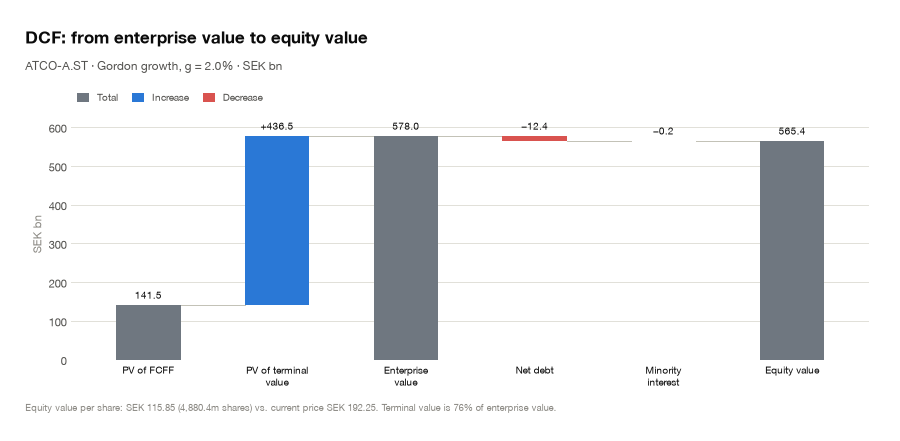

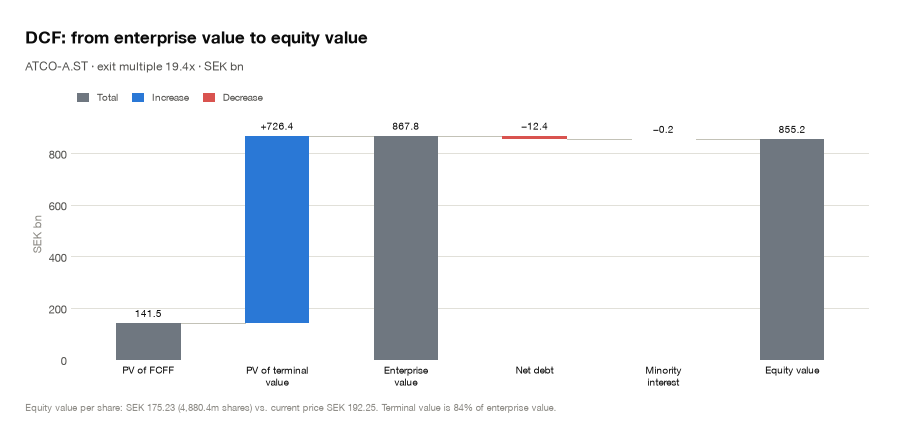

In [26]:
show(charts["dcf_bridge_gordon"], "dcf_bridge_gordon")
show(charts["dcf_bridge_exit"], "dcf_bridge_exit")

### 6.6 Känslighet

Värde per aktie för olika WACC och tillväxt (Gordon) respektive WACC och exit-multipel. Football field-stapeln för DCF tas ur de här tabellerna: lågt värde är WACC + 1 procentenhet och g minus 0,5 (eller multipel minus 1,0x), högt värde är tvärtom.

In [27]:
gordon_grid = dcf.sensitivity_gordon.copy()
gordon_grid.index = [f"WACC {v:.2%}" for v in gordon_grid.index]
gordon_grid.columns = [f"g {v:.1%}" for v in gordon_grid.columns]
exit_grid = dcf.sensitivity_exit.copy()
exit_grid.index = [f"WACC {v:.2%}" for v in exit_grid.index]
exit_grid.columns = [f"{v:.1f}x" for v in exit_grid.columns]
display(gordon_grid.round(1), exit_grid.round(1))

,g 1.0%,g 1.5%,g 2.0%,g 2.5%,g 3.0%
WACC 6.65%,120.80,129.70,140.40,153.70,170.70
WACC 7.15%,111.10,118.30,126.90,137.40,150.50
WACC 7.65%,102.80,108.80,115.80,124.30,134.50
WACC 8.15%,95.60,100.70,106.60,113.50,121.70
WACC 8.65%,89.40,93.70,98.70,104.40,111.10


,17.4x,18.4x,19.4x,20.4x,21.4x
WACC 6.65%,167.00,175.00,183.00,191.00,199.10
WACC 7.15%,163.40,171.20,179.10,186.90,194.80
WACC 7.65%,159.90,167.60,175.20,182.90,190.60
WACC 8.15%,156.50,164.00,171.50,179.00,186.50
WACC 8.65%,153.20,160.60,167.90,175.20,182.50


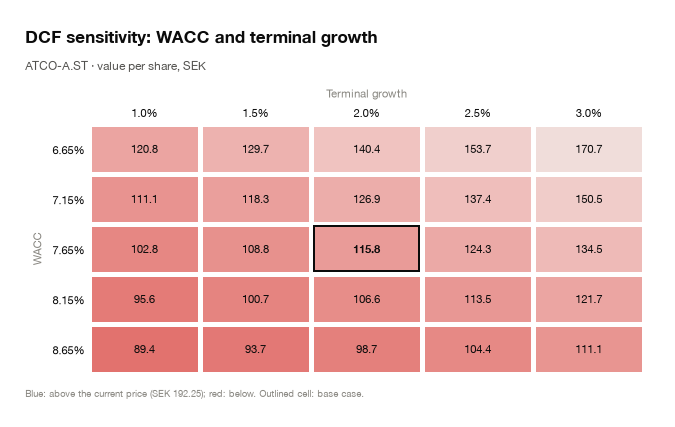

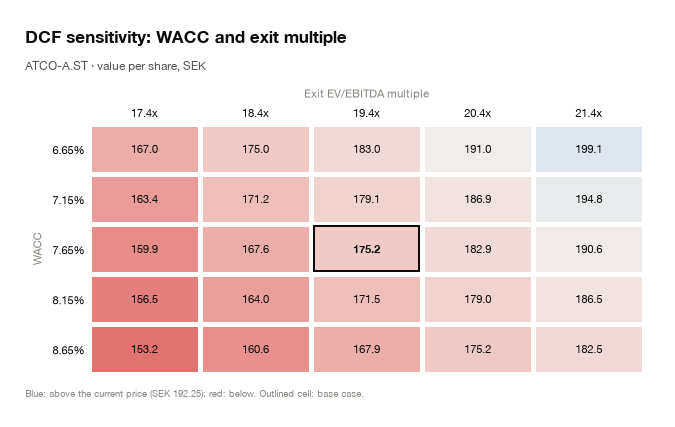

In [28]:
show(charts["dcf_sensitivity_wacc_growth"], "dcf_sensitivity_wacc_growth")
show(charts["dcf_sensitivity_wacc_exit_multiple"], "dcf_sensitivity_wacc_exit_multiple")

### 6.7 Vad kräver dagens kurs?

Gordon-värdet är 116 kr och kursen 192 kr. I stället för att gissa varför räknar vi baklänges med motorns egen kärna (`dcf_core`): vilket värde på en enda drivare, med allt annat lika, gör att DCF:en ger exakt dagens kurs?

In [29]:
core = dcf.core_inputs


def gordon(**overrides):
    """Gordon value per share of the base case with some core inputs replaced."""
    return float(dcf_model.dcf_core(**{**core, **overrides}).value_per_share_gordon[0])


def exit_value(**overrides):
    return float(dcf_model.dcf_core(**{**core, **overrides}).value_per_share_exit[0])


base_growth = np.asarray(core["revenue_growth"], dtype=float)
base_margin = float(np.asarray(core["ebitda_margin"], dtype=float)[0])
years_n = len(base_growth)

implied_wacc = brentq(lambda v: gordon(wacc=v) - price, 0.03, core["wacc"])
implied_g = brentq(lambda v: gordon(terminal_growth=v) - price, core["terminal_growth"], 0.07)
implied_margin = brentq(lambda v: gordon(ebitda_margin=np.full(years_n, v)) - price, 0.2, 0.6)
implied_shift = brentq(lambda v: gordon(revenue_growth=base_growth + v) - price, 0.0, 0.3)
implied_exit = brentq(lambda v: exit_value(exit_multiple=v) - price, 5.0, 40.0)

implied_table = pd.DataFrame(
    {
        "base case": [
            f"{core['wacc']:.2%}",
            f"{core['terminal_growth']:.2%}",
            f"{base_margin:.1%}",
            f"{base_growth.mean():.1%}",
            f"{core['exit_multiple']:.1f}x",
        ],
        "needed for value = price": [
            f"{implied_wacc:.2%}",
            f"{implied_g:.2%}",
            f"{implied_margin:.1%}",
            f"{(base_growth + implied_shift).mean():.1%}",
            f"{implied_exit:.1f}x",
        ],
    },
    index=[
        "WACC (Gordon)",
        "terminal growth (Gordon)",
        "EBITDA margin, all years (Gordon)",
        "average revenue growth years 1-5 (Gordon)",
        "exit multiple (exit method)",
    ],
)
implied_table

,base case,needed for value = price
WACC (Gordon),7.65%,5.39%
terminal growth (Gordon),2.00%,4.64%
"EBITDA margin, all years (Gordon)",26.4%,40.0%
average revenue growth years 1-5 (Gordon),4.0%,16.8%
exit multiple (exit method),19.4x,21.7x


In [30]:
# Combinations of WACC and terminal growth that reproduce the price (everything else at base).
iso = pd.Series(
    {
        g: brentq(lambda v, g=g: gordon(wacc=v, terminal_growth=g) - price, g + 0.006, 0.12)
        for g in np.arange(0.020, 0.0451, 0.005)
    },
    name="WACC that gives the current price (%)",
)
(iso * 100).round(2).rename(index=lambda g: f"g = {g:.1%}").to_frame().T

,g = 2.0%,g = 2.5%,g = 3.0%,g = 3.5%,g = 4.0%,g = 4.5%
WACC that gives the current price (%),5.39,5.81,6.24,6.67,7.10,7.53


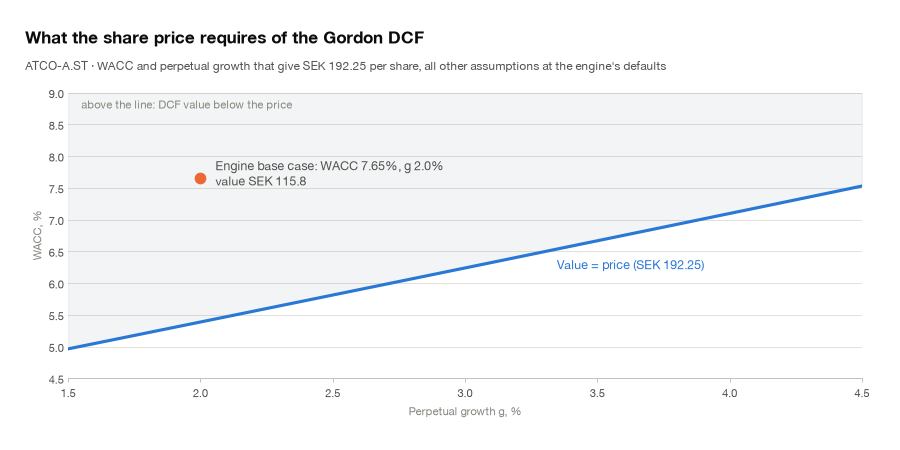

In [31]:
grid_g = np.linspace(0.015, 0.045, 31)
grid_wacc = [
    brentq(lambda v, g=g: gordon(wacc=v, terminal_growth=g) - price, g + 0.006, 0.12)
    for g in grid_g
]
fig, ax = style.new_figure(
    "What the share price requires of the Gordon DCF",
    f"{TICKER} · WACC and perpetual growth that give SEK {price:.2f} per share, "
    "all other assumptions at the engine's defaults",
    figsize=(10.0, 5.0),
)
ax.plot(grid_g * 100, np.asarray(grid_wacc) * 100, color=style.BLUE, linewidth=2.5)
ax.scatter(
    [core["terminal_growth"] * 100], [core["wacc"] * 100], color=style.ORANGE, s=70, zorder=3
)
ax.annotate(
    f"Engine base case: WACC {core['wacc']:.2%}, g {core['terminal_growth']:.1%}\n"
    f"value SEK {dcf.value_per_share_gordon:.1f}",
    (core["terminal_growth"] * 100, core["wacc"] * 100),
    xytext=(12, 4),
    textcoords="offset points",
    fontsize=10,
    color=style.SECONDARY,
    va="center",
)
ax.annotate(
    f"Value = price (SEK {price:.2f})",
    (grid_g[18] * 100, grid_wacc[18] * 100),
    xytext=(10, -14),
    textcoords="offset points",
    fontsize=10,
    color=style.BLUE,
)
ax.fill_between(grid_g * 100, np.asarray(grid_wacc) * 100, 9.0, color=style.NEUTRAL, alpha=0.08)
ax.text(1.55, 8.75, "above the line: DCF value below the price", fontsize=9, color=style.MUTED)
ax.set_xlabel("Perpetual growth g, %")
ax.set_ylabel("WACC, %")
ax.set_ylim(4.5, 9.0)
ax.set_xlim(1.5, 4.5)
show(style.finalize(fig), "implied_wacc_growth")

Ingen enskild drivare kan rimligen flyttas så långt: en WACC på 5,4 %, en evig tillväxt på 4,6 % eller en EBITDA-marginal på 40 %. Men kombinationer räcker längre än man tror. WACC 6,65 % och g 3,0 % ger 171 kr (se känslighetstabellen), och längs linjen i diagrammet ger till exempel g 3,0 % och WACC 6,2 % exakt dagens kurs.

Tre modellval drar också nedåt. Vi mäter dem med samma kärna:

In [32]:
# 1. Terminal capex floor (capex >= D&A in the normalized terminal year).
no_floor = gordon(terminal_capex_floor=False)

# 2. A slower fade: growth falls linearly from the year-1 rate to 2 % over 10 years, not 5.
slow_fade = gordon(
    revenue_growth=np.linspace(base_growth[0], core["terminal_growth"], 10),
    ebitda_margin=np.full(10, base_margin),
)

# 3. No stub period: the model values the company at the start of FY2026 but uses net debt
#    of 30 September 2026. Rough correction: roll the enterprise value forward at the WACC
#    and take out the cash flow already received (and already sitting in net debt).
elapsed = (market.as_of - date(statements.latest_year, 12, 31)).days / 365
rolled = dcf.enterprise_value_gordon * ((1 + dcf.wacc) ** elapsed - 1)
received = dcf.forecast["fcff"].iloc[0] * elapsed
stub = (rolled - received) / market.shares_outstanding

# 4. IFRS 16: lease payments are neither in EBITDA nor in capex. Proxy for the yearly
#    payment: the current lease liability of FY2025, discounted over the five explicit years.
lease_payment = raw_bs["Current Capital Lease Obligation"].iloc[-1]
lease_overstatement = (
    lease_payment * dcf.forecast["discount_factor"].sum() / market.shares_outstanding
)

model_effects = pd.Series(
    {
        "base case (Gordon)": dcf.value_per_share_gordon,
        "without the terminal capex floor": no_floor,
        "10-year instead of 5-year growth fade": slow_fade,
        "rough stub-period correction (SEK per share, add)": stub,
        "IFRS 16 lease payments missing in years 1-5 (per share, subtract)": lease_overstatement,
    }
)
model_effects.to_frame("SEK per share")

,SEK per share
base case (Gordon),115.85
without the terminal capex floor,124.69
10-year instead of 5-year growth fade,126.89
"rough stub-period correction (SEK per share, add)",2.38
"IFRS 16 lease payments missing in years 1-5 (per share, subtract)",1.51


Capex-golvet kostar ungefär 9 kr per aktie. För Atlas Copco är golvet ändå försvarbart: avskrivningarna var 9,5 mdkr 2025 mot capex 6,2 mdkr, men i avskrivningarna ligger också leasade tillgångar, och leasingbetalningar (ungefär 1,8 mdkr om året) finns inte med i capex. En långsammare inbromsning av tillväxten (tio år i stället för fem) ger ungefär 11 kr, stubbperioden ett par kronor, och leasingeffekten drar ett par kronor åt andra hållet. Inget av detta förklarar gapet på 76 kr. Det gör bara avkastningskravet, den eviga tillväxten eller multipeln.

## 7. LBO: vad kan en riskkapitalköpare betala?

En LBO-modell ställer en annan fråga än DCF:en. LBO:n räknar på samma rörelseprognos som DCF:en (pipelinen skickar över tillväxt, marginal, avskrivningar, capex, rörelsekapital och skatt) och säljer till samma exit-multipel. En köpare betalar kurs plus budpremie, lånar en stor del av köpeskillingen, låter bolagets kassaflöde betala av lånen i fem år och säljer sedan. Avkastningen på det egna kapitalet mäts som IRR (årlig avkastning) och MOIC (pengarna tillbaka, gånger).

Ett uppköp av ett bolag värt över 900 mdkr är inte realistiskt. Läs avsnittet som en räkneövning som visar mekaniken och som ger ett golv: vad bolaget vore värt för en ägare som kräver 20 % om året.

### 7.1 Källor och användning

In [33]:
lbo = report.lbo
la = lbo.assumptions
entry = pd.Series(
    {
        "market price (SEK)": lbo.market_price,
        "takeover premium": la.takeover_premium,
        "offer price per share (SEK)": lbo.entry_price_per_share,
        "equity purchase price (SEK bn)": lbo.entry_equity_value / BN,
        "entry enterprise value (SEK bn)": lbo.entry_enterprise_value / BN,
        "entry EBITDA, FY2025 (SEK bn)": lbo.entry_ebitda / BN,
        "entry EV / EBITDA (x)": lbo.entry_multiple,
        "senior debt (SEK bn)": lbo.senior_debt / BN,
        "subordinated debt (SEK bn)": lbo.subordinated_debt / BN,
        "debt / EBITDA (x)": lbo.leverage,
        "sponsor equity (SEK bn)": lbo.sponsor_equity / BN,
        "sponsor equity share of new capital": lbo.equity_share,
        "senior / subordinated interest rate": f"{la.senior_rate:.2%} / {la.subordinated_rate:.2%}",
    }
)
print("debt sizing notes:", lbo.sizing_notes or "no cap was binding")
display(entry.to_frame("value"))
sources_uses = lbo.sources_and_uses.copy()
sources_uses["amount"] = sources_uses["amount"] / BN
sources_uses["pct"] = sources_uses["pct"] * 100
sources_uses.rename(columns={"amount": "SEK bn", "pct": "% of side"})

debt sizing notes: no cap was binding


,value
market price (SEK),192.25
takeover premium,0.30
offer price per share (SEK),249.93
equity purchase price (SEK bn),"1,219.75"
entry enterprise value (SEK bn),"1,232.36"
"entry EBITDA, FY2025 (SEK bn)",44.08
entry EV / EBITDA (x),27.96
senior debt (SEK bn),176.33
subordinated debt (SEK bn),66.12
debt / EBITDA (x),5.50


,side,item,SEK bn,% of side
0,sources,Senior term loan,176.33,13.67
1,sources,Subordinated debt,66.12,5.13
2,sources,Existing cash on balance sheet,25.11,1.95
3,sources,Sponsor equity,"1,022.55",79.26
4,uses,Purchase of equity,"1,219.75",94.55
5,uses,Refinancing of existing debt,37.51,2.91
6,uses,Redemption of preferred equity,0.00,0.00
7,uses,Transaction fees,24.65,1.91
8,uses,Financing fees,4.85,0.38
9,uses,Minimum cash to balance sheet,3.37,0.26


Skulden sätts till 5,5 gånger EBITDA (4,0 senior plus 1,5 efterställd), det vill säga 242 mdkr. Men budet värderar bolaget till 28 gånger EBITDA, så lånen räcker bara till en femtedel. Köparen måste själv skjuta till över 1 000 mdkr. Redan här syns varför affären inte går ihop: hävstången som en LBO lever på finns knappt.

### 7.2 Skuldschema

In [34]:
schedule = lbo.debt_schedule
rows = [
    "cash_flow_available_for_debt_service",
    "cash_interest",
    "senior_mandatory_amortization",
    "senior_cash_sweep",
    "senior_closing",
    "subordinated_closing",
    "revolver_closing",
    "cash_closing",
    "net_debt_closing",
]
display((schedule[rows] / BN).T)
schedule[["net_debt_to_ebitda", "interest_coverage"]].T

fiscal_year,2026,2027,2028,2029,2030
cash_flow_available_for_debt_service,33.53,35.63,37.51,39.11,40.06
cash_interest,19.80,18.84,17.67,16.27,14.67
senior_mandatory_amortization,8.82,8.82,8.82,8.82,8.82
senior_cash_sweep,4.71,7.80,10.88,13.90,16.50
senior_closing,162.80,146.19,126.49,103.78,78.46
subordinated_closing,66.12,66.12,66.12,66.12,66.12
revolver_closing,0.00,0.00,0.00,0.00,0.00
cash_closing,3.57,3.75,3.90,4.01,4.09
net_debt_closing,225.35,208.56,188.72,165.88,140.49


fiscal_year,2026,2027,2028,2029,2030
net_debt_to_ebitda,4.78,4.22,3.67,3.13,2.60
interest_coverage,2.38,2.63,2.91,3.26,3.69


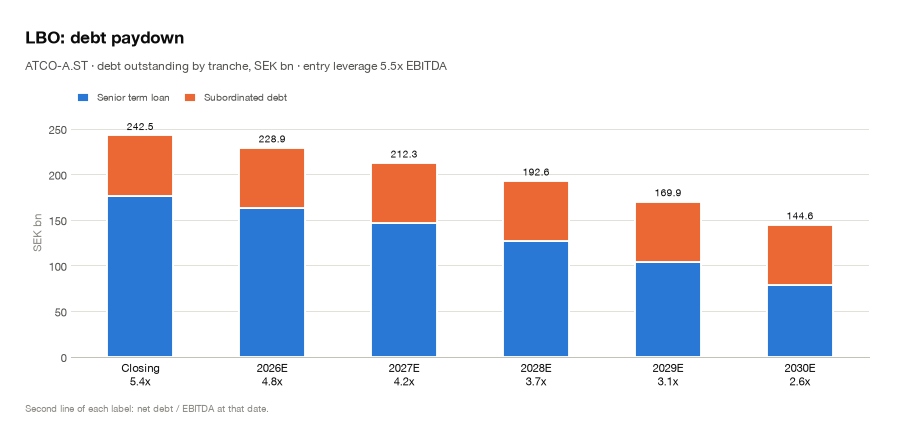

In [35]:
show(charts["lbo_debt_paydown"], "lbo_debt_paydown")

Räntan räknas på årets ingående skuld. Efter ränta och 5 % obligatorisk amortering går allt överskott till att betala av seniorlånet (cash sweep). Det efterställda lånet betalas först vid exit.

### 7.3 Avkastning och varifrån den kommer

In [36]:
returns = pd.Series(
    {
        "exit year": lbo.exit_year,
        "exit EBITDA (SEK bn)": lbo.exit_ebitda / BN,
        "exit multiple (x), same as the DCF": lbo.exit_multiple,
        "exit enterprise value (SEK bn)": lbo.exit_enterprise_value / BN,
        "net debt at exit (SEK bn)": lbo.exit_net_debt / BN,
        "minority interest (SEK bn)": lbo.exit_minority_interest / BN,
        "equity value at exit (SEK bn)": lbo.exit_equity_value / BN,
        "sponsor equity invested (SEK bn)": lbo.sponsor_equity / BN,
        "MOIC (x)": lbo.moic,
        "IRR (%)": lbo.irr * 100,
    }
)
display(returns.to_frame("value"))
attribution = lbo.attribution.copy()
attribution["amount"] = attribution["amount"] / BN
attribution.rename(columns={"amount": "SEK bn"})

,value
exit year,"2,030.00"
exit EBITDA (SEK bn),54.04
"exit multiple (x), same as the DCF",19.43
exit enterprise value (SEK bn),"1,050.17"
net debt at exit (SEK bn),140.49
minority interest (SEK bn),0.22
equity value at exit (SEK bn),909.45
sponsor equity invested (SEK bn),"1,022.55"
MOIC (x),0.89
IRR (%),-2.32


,SEK bn,share
component,,
ebitda_growth,278.51,2.46
multiple_expansion,-460.71,-4.07
debt_paydown,98.59,0.87
fees,-29.50,-0.26
equity_floor,0.00,0.00
total_value_creation,-113.10,-1.00


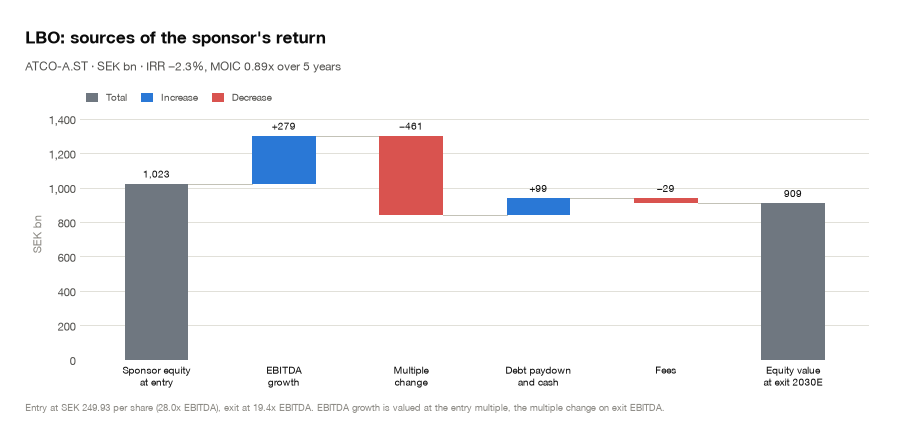

In [37]:
show(charts["lbo_returns_waterfall"], "lbo_returns_waterfall")

Till kurs plus 30 % premie förlorar köparen pengar: IRR är minus 2,3 % och MOIC 0,89. Vinsttillväxt och amortering ger tillsammans 377 mdkr, men köparen går in på 28 gånger EBITDA och antas sälja på 19,4 gånger, och det kostar 461 mdkr. Kolumnen `share` anger varje post som andel av det totala värdetappets belopp.

### 7.4 Känslighet och betalningsförmåga

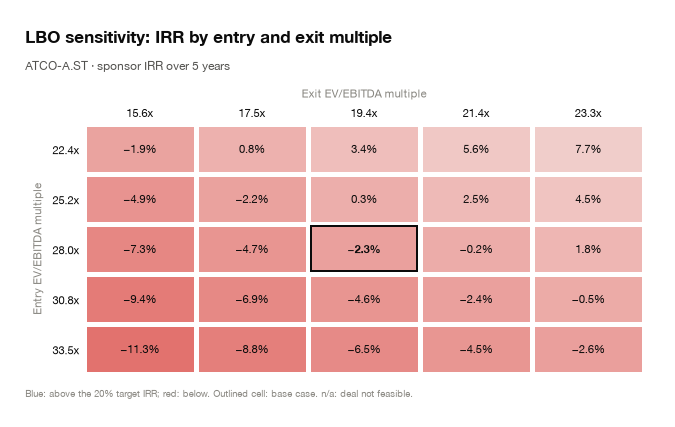

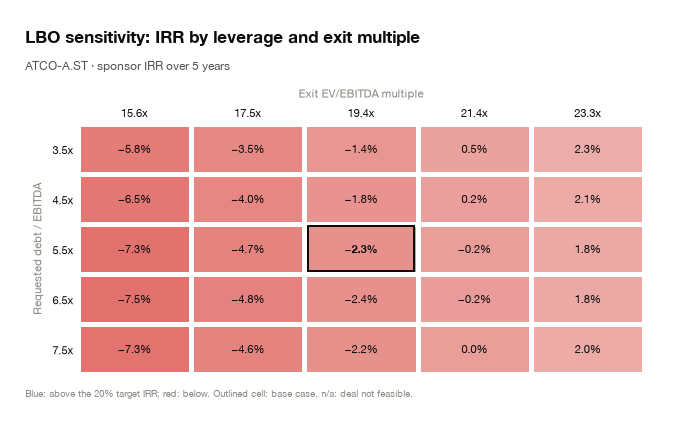

In [38]:
show(charts["lbo_sensitivity_entry_exit"], "lbo_sensitivity_entry_exit")
show(charts["lbo_sensitivity_leverage_exit"], "lbo_sensitivity_leverage_exit")

In [39]:
net_claims = lbo.entry_enterprise_value - lbo.entry_equity_value
ability = pd.DataFrame(
    {
        "price per share (SEK)": pd.Series(lbo.ability_to_pay),
        "status": pd.Series(lbo.ability_to_pay_status),
    }
).sort_index()
ability["vs. market price"] = ability["price per share (SEK)"] / price - 1
ability["implied entry EV / EBITDA (x)"] = (
    ability["price per share (SEK)"] * lbo.shares_outstanding + net_claims
) / lbo.entry_ebitda
ability.index = [f"target IRR {k:.0%}" for k in ability.index]
ability

,price per share (SEK),status,vs. market price,implied entry EV / EBITDA (x)
target IRR 15%,135.34,solved,-0.30,15.27
target IRR 20%,117.93,solved,-0.39,13.34
target IRR 25%,104.38,solved,-0.46,11.84


Betalningsförmågan (ability to pay) vänder på frågan: vilket pris ger exakt 15, 20 eller 25 % IRR? Svaret är 135, 118 respektive 104 kr. Vid 20 % motsvarar det 13,3 gånger EBITDA. Det ligger nära Gordon-DCF:en (116 kr) av ett enkelt skäl: båda metoderna säger att kassaflödena inte räcker till dagens värdering om man kräver en avkastning långt över marknadens.

## 8. Monte Carlo: ett intervall i stället för en punkt

Monte Carlo-modellen drar 10 000 scenarier runt DCF:ens basfall och räknar Gordon-värdet för vart och ett. Fyra drivare är slumpmässiga: omsättningstillväxt (samma förskjutning alla fem åren), EBITDA-marginal (också en parallell förskjutning), WACC och evig tillväxt. Tillväxt och marginal är korrelerade med +0,3, resten är oberoende. Fördelningarna är trunkerade normalfördelningar, kapade vid två standardavvikelser.

In [40]:
mc = report.monte_carlo
hist_growth_std = ratios["revenue growth"].std()
default_stds = mc_model.default_driver_stds(company, dcf)
base_levels = {
    "revenue_growth": base_growth[0],
    "ebitda_margin": base_margin,
    "wacc": core["wacc"],
    "terminal_growth": core["terminal_growth"],
}
spec_table = pd.DataFrame(
    {
        driver: {
            "base level": base_levels[driver],
            "std before truncation": mc.config.spec(driver).std,
            "lowest draw allowed": base_levels[driver] + mc.config.spec(driver).low,
            "highest draw allowed": base_levels[driver] + mc.config.spec(driver).high,
            "std of the sampled values": mc.inputs[driver].std(),
        }
        for driver in mc_model.DRIVERS
    }
).T
print(
    f"historical std of yearly revenue growth: {hist_growth_std:.1%} (3 observations); "
    f"x {mc_model.GROWTH_VOL_SCALE} = {hist_growth_std * mc_model.GROWTH_VOL_SCALE:.1%}, "
    f"capped at {mc_model.GROWTH_STD_BAND[1]:.0%}"
)
print("default stds:", {k: round(v, 4) for k, v in default_stds.items()})
(spec_table * 100).round(2)

historical std of yearly revenue growth: 14.0% (3 observations); x 0.5 = 7.0%, capped at 5%
default stds: {'revenue_growth': 0.05, 'ebitda_margin': 0.01, 'wacc': 0.01, 'terminal_growth': 0.005}


,base level,std before truncation,lowest draw allowed,highest draw allowed,std of the sampled values
revenue_growth,6.00,5.00,-4.00,16.00,4.37
ebitda_margin,26.40,1.00,24.40,28.40,0.89
wacc,7.65,1.00,5.65,9.65,0.88
terminal_growth,2.00,0.50,1.00,3.00,0.45


Standardavvikelserna är antaganden, och det syns tydligt för tillväxten. Den historiska spridningen bygger på tre observationer, varav en är +22 %. Halverad blir den 7 procentenheter och slår i motorns tak på 5. WACC får 1 procentenhet och evig tillväxt 0,5 som fasta konventioner.

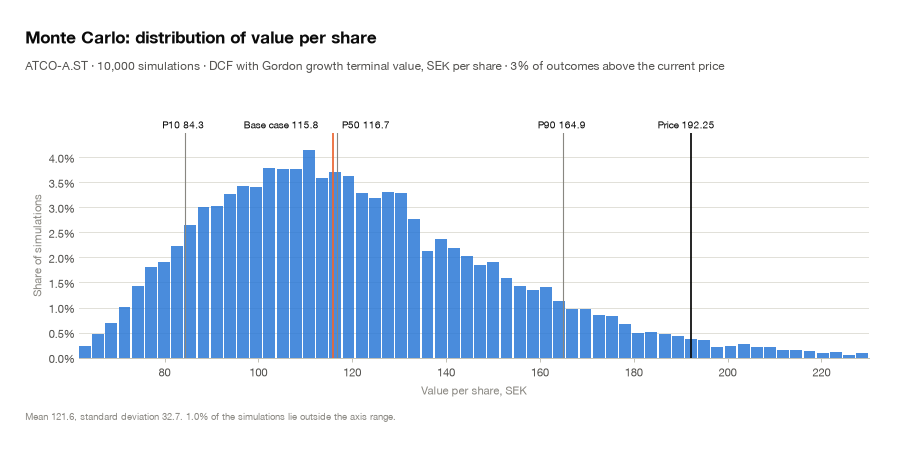

In [41]:
show(charts["mc_histogram"], "mc_histogram")

In [42]:
percentiles = pd.Series(mc.percentiles, name="Gordon value per share (SEK)")
percentiles.index = [f"P{level}" for level in percentiles.index]
exit_percentiles = np.nanpercentile(mc.valid_values_exit, [10, 50, 90])
stats = pd.Series(
    {
        "base case": mc.base_value,
        "median": mc.median,
        "mean": mc.mean,
        "standard deviation": mc.std,
        "standard error of the mean": mc.standard_error,
        "share of simulations above the price (%)": mc.prob_above_price * 100,
        "invalid simulations": mc.n_non_finite,
        "exit-multiple value P10": exit_percentiles[0],
        "exit-multiple value P50": exit_percentiles[1],
        "exit-multiple value P90": exit_percentiles[2],
    }
)
display(percentiles.to_frame().T, stats.to_frame("value"))

,P5,P10,P25,P50,P75,P90,P95
Gordon value per share (SEK),77.55,84.29,97.98,116.74,139.89,164.92,181.87


,value
base case,115.85
median,116.74
mean,121.64
standard deviation,32.69
standard error of the mean,0.33
share of simulations above the price (%),3.26
invalid simulations,0.00
exit-multiple value P10,132.55
exit-multiple value P50,174.68
exit-multiple value P90,230.38


Fördelningen är sned åt höger. Medelvärdet (122) ligger över medianen (117), som ligger nära basfallet (116). Det beror på formeln: värdet beter sig som `1 / (WACC - g)`, som är konvext, så symmetrisk osäkerhet i indata ger en lång svans uppåt. Det är en matematisk egenskap och inget tecken på uppsida. Därför redovisar motorn medianen som mittvärde.

Tornadodiagrammet flyttar en drivare i taget mellan sin 10:e och 90:e percentil. Variansbidraget är en grov rangordning som bygger på rangkorrelation, inte en exakt uppdelning.

,input_low,input_high,value_low,value_high,swing
driver,,,,,
revenue_growth,0.00,0.12,90.66,147.05,56.39
wacc,0.06,0.09,146.12,96.04,50.08
terminal_growth,0.01,0.03,107.60,126.02,18.42
ebitda_margin,0.25,0.28,109.19,122.50,13.31


driver,revenue_growth,ebitda_margin,wacc,terminal_growth
variance_contribution,0.51,0.12,0.32,0.05


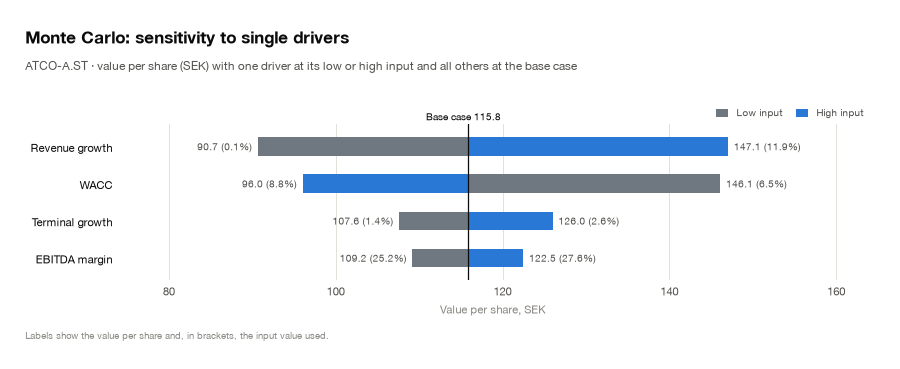

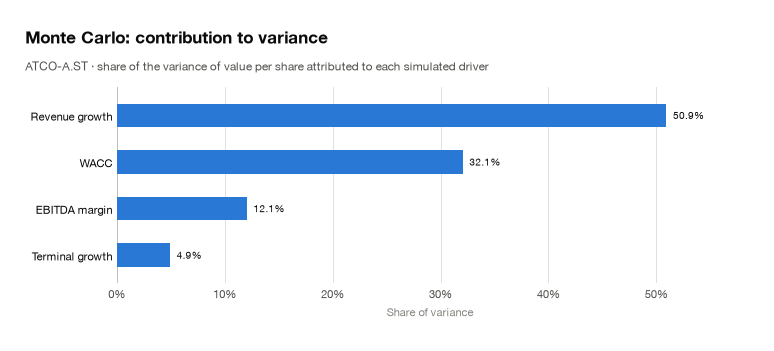

In [43]:
display(mc.tornado, mc.variance_contribution.to_frame().T)
show(charts["mc_tornado"], "mc_tornado")
show(charts["mc_variance_contribution"], "mc_variance_contribution")

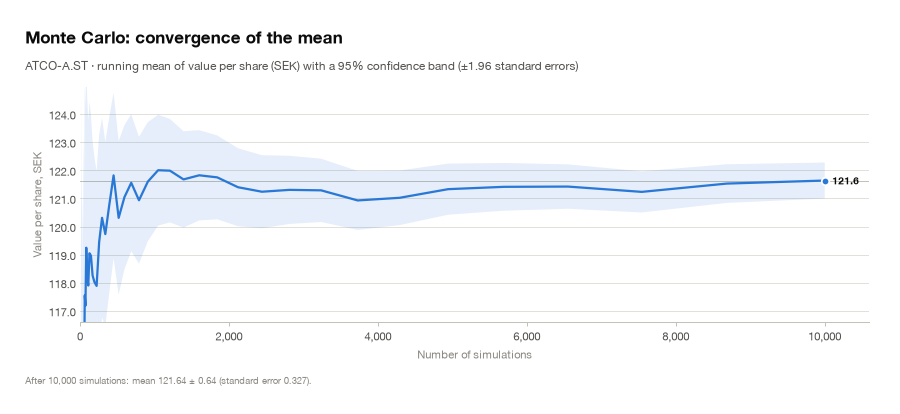

,n,running_mean,running_median,standard_error
9,36,112.87,106.38,4.20
19,146,118.96,116.54,2.56
29,596,121.05,116.31,1.31
39,2442,121.24,116.27,0.66
49,10000,121.64,116.74,0.33


In [44]:
show(charts["mc_convergence"], "mc_convergence")
mc.convergence.iloc[[9, 19, 29, 39, 49]]

Konvergensen visar att 10 000 dragningar räcker för att skatta medelvärdet inom några tiondels kronor. Men den precisionen gäller bara simuleringen. Den säger ingenting om huruvida fördelningarna vi matade in är riktiga. Två kontrollkörningar visar skillnaden: fler dragningar med ett annat frö ändrar nästan ingenting, medan ett annat antagande om tillväxtens spridning (3 i stället för 5 procentenheter) flyttar hela intervallet.

In [45]:
more_draws = mc_model.run_monte_carlo(
    company, config=mc_model.MonteCarloConfig(n_simulations=100_000, seed=7), dcf_result=dcf
)
narrow_growth = mc_model.run_monte_carlo(
    company,
    config=mc_model.MonteCarloConfig(revenue_growth=mc_model.DistributionSpec(std=0.03)),
    dcf_result=dcf,
)
mc_variants = pd.DataFrame(
    {
        label: {
            "P10": result.percentiles[10],
            "P50": result.percentiles[50],
            "P90": result.percentiles[90],
            "mean": result.mean,
            "share above price (%)": result.prob_above_price * 100,
        }
        for label, result in (
            ("default: 10,000 draws, seed 42", mc),
            ("100,000 draws, seed 7", more_draws),
            ("growth std 3 pp instead of 5 pp", narrow_growth),
        )
    }
).T
mc_variants

,P10,P50,P90,mean,share above price (%)
"default: 10,000 draws, seed 42",84.29,116.74,164.92,121.64,3.26
"100,000 draws, seed 7",84.01,116.32,165.18,121.30,3.27
growth std 3 pp instead of 5 pp,90.01,116.65,155.37,120.44,1.65


## 9. Football field

Alla metoder i en bild. Varje stapel går från metodens låga till höga värde, romben är basvärdet och den svarta linjen dagens kurs. Den nedersta stapeln är inget värde utan kursens spann de senaste 52 veckorna (veckostängningar).

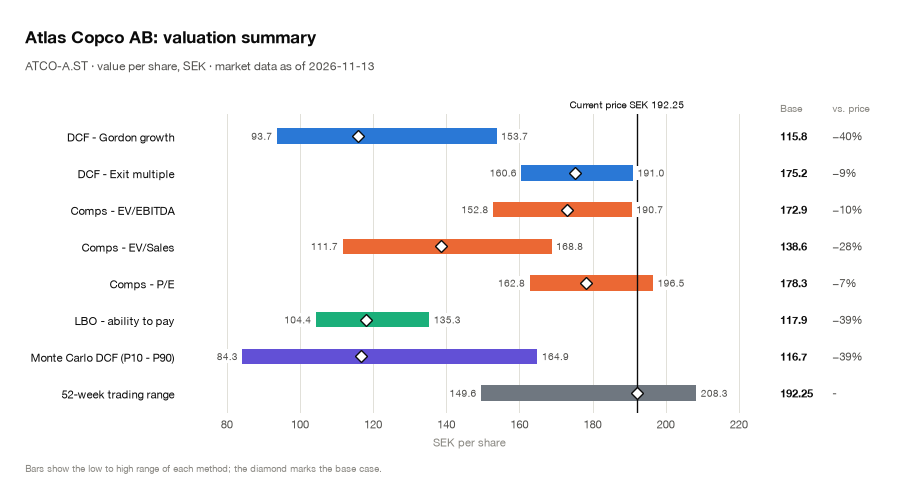

,low,base,high,base vs. price
DCF - Gordon growth,93.73,115.85,153.74,-0.40
DCF - Exit multiple,160.55,175.23,191.04,-0.09
Comps - EV/EBITDA,152.81,172.93,190.71,-0.10
Comps - EV/Sales,111.67,138.62,168.80,-0.28
Comps - P/E,162.82,178.33,196.54,-0.07
LBO - ability to pay,104.38,117.93,135.34,-0.39
Monte Carlo DCF (P10 - P90),84.29,116.74,164.92,-0.39
52-week trading range,149.55,192.25,208.34,0.00


In [46]:
show(charts["football_field"], "football_field")
rows = viz.report_valuations(report)
field = pd.DataFrame(
    {
        row.label: {
            "low": row.low,
            "base": row.base,
            "high": row.high,
            "base vs. price": row.base / price - 1,
        }
        for row in rows
    }
).T
field

## 10. Justerat fall

Hittills har allt varit motorns standardantaganden. Efter att ha jämfört dem med historiken (avsnitt 2 och 6.1) ändrar jag två saker. Allt annat låter jag stå, med motivering i rapporten.

1. **Skattesats 21,9 % i stället för 20,6 %.** Den effektiva skatten har legat över den svenska skattesatsen alla fyra åren. Jag använder snittet för de tre senaste åren, samma fönster som motorn använder för marginalerna.
2. **Rörelsekapital 13,3 % av omsättningen i stället för 25,2 %.** Motorns smala mått bortser från övriga rörelseskulder. Det breda måttet (omsättningstillgångar utom kassa, minus kortfristiga skulder utom lån) är stabilt kring 13 %. Även det är troligen i överkant: mellan 2022 och 2025 växte det breda rörelsekapitalet med 2,1 mdkr medan omsättningen växte med 27 mdkr.
Överstyrningen görs med pipelinens parameter `dcf_assumptions`. LBO:n behöver ingen egen överstyrning: när `lbo_assumptions` inte anges tar pipelinen DCF:ens rörelseprognos, så ändringarna följer med dit automatiskt.

In [47]:
window_years = dcf_model.HISTORY_WINDOW
tax_adjusted = float(ratios["effective tax rate"].iloc[-window_years:].mean())
nwc_adjusted = float((broad_nwc / inc["revenue"]).iloc[-window_years:].mean())
print(f"adjusted tax rate {tax_adjusted:.4f}, adjusted NWC / revenue {nwc_adjusted:.4f}")
print(
    f"change in broad NWC 2022-2025: {(broad_nwc.iloc[-1] - broad_nwc.iloc[0]) / BN:.1f} bn, "
    f"change in revenue: {(inc['revenue'].iloc[-1] - inc['revenue'].iloc[0]) / BN:.1f} bn"
)

dcf_default = dcf_model.default_assumptions(company, report.params)
dcf_adjusted = replace(dcf_default, tax_rate=tax_adjusted, nwc_pct_revenue=nwc_adjusted)


adjusted = pipeline.run_valuation(
    TICKER,
    offline=True,
    dcf_assumptions=dcf_adjusted,
)
print("warnings:", adjusted.warnings or "none")
print("notes:", *adjusted.notes, sep="\n  ")
print(
    f"LBO follows the DCF: tax rate {adjusted.lbo.assumptions.tax_rate:.4f}, NWC / revenue "
    f"{adjusted.lbo.assumptions.nwc_pct_revenue:.4f}, revenue in 2030 "
    f"{adjusted.lbo.forecast['revenue'].iloc[-1] / BN:.1f} bn "
    f"(DCF {adjusted.dcf.forecast['revenue'].iloc[-1] / BN:.1f} bn)"
)

adjusted tax rate 0.2191, adjusted NWC / revenue 0.1331
change in broad NWC 2022-2025: 2.1 bn, change in revenue: 27.0 bn
warnings: none
notes:
  DCF: the peer beta is based on the 12 peers selected by comps (12 usable betas); the exit multiple is the comps EV/EBITDA median.
  LBO: the operating forecast (revenue growth, EBITDA margin, D&A, capex, NWC and tax rate) is the one of the DCF.
  LBO: the exit multiple is the exit multiple of the DCF (comps median EV/EBITDA (11 peers)).
LBO follows the DCF: tax rate 0.2191, NWC / revenue 0.1331, revenue in 2030 204.7 bn (DCF 204.7 bn)


In [48]:
# One change at a time, to see what each override does.
steps = {
    "engine defaults": report,
    "tax rate only": pipeline.run_valuation(
        TICKER,
        offline=True,
        run_monte_carlo=False,
        dcf_assumptions=replace(dcf_default, tax_rate=tax_adjusted),
    ),
    "NWC only": pipeline.run_valuation(
        TICKER,
        offline=True,
        run_monte_carlo=False,
        dcf_assumptions=replace(dcf_default, nwc_pct_revenue=nwc_adjusted),
    ),
    "adjusted case (both)": adjusted,
}
pd.DataFrame(
    {
        label: {
            "DCF Gordon": result.dcf.value_per_share_gordon,
            "DCF exit multiple": result.dcf.value_per_share_exit,
            "LBO at 20% IRR": result.lbo.ability_to_pay[0.20],
            "WACC (%)": result.dcf.wacc * 100,
        }
        for label, result in steps.items()
    }
).T

,DCF Gordon,DCF exit multiple,LBO at 20% IRR,WACC (%)
engine defaults,115.85,175.23,117.93,7.65
tax rate only,113.88,174.78,117.78,7.65
NWC only,117.87,176.00,118.34,7.65
adjusted case (both),115.90,175.54,118.18,7.65


In [49]:
def valuation_frame(result):
    return pd.DataFrame(
        {
            row.label: {"low": row.low, "base": row.base, "high": row.high}
            for row in viz.report_valuations(result)
        }
    ).T


comparison = pd.concat(
    {"default": valuation_frame(report), "adjusted": valuation_frame(adjusted)}, axis=1
)
comparison[("change", "base")] = comparison[("adjusted", "base")] - comparison[("default", "base")]
comparison

default               adjusted               change
                                low   base   high      low   base   high   base
DCF - Gordon growth           93.73 115.85 153.74    93.61 115.90 154.14   0.06
DCF - Exit multiple          160.55 175.23 191.04   160.85 175.54 191.35   0.31
Comps - EV/EBITDA            152.81 172.93 190.71   152.81 172.93 190.71   0.00
Comps - EV/Sales             111.67 138.62 168.80   111.67 138.62 168.80   0.00
Comps - P/E                  162.82 178.33 196.54   162.82 178.33 196.54   0.00
LBO - ability to pay         104.38 117.93 135.34   104.58 118.18 135.65   0.25
Monte Carlo DCF (P10 - P90)   84.29 116.74 164.92    83.62 116.94 165.74   0.20
52-week trading range        149.55 192.25 208.34   149.55 192.25 208.34   0.00

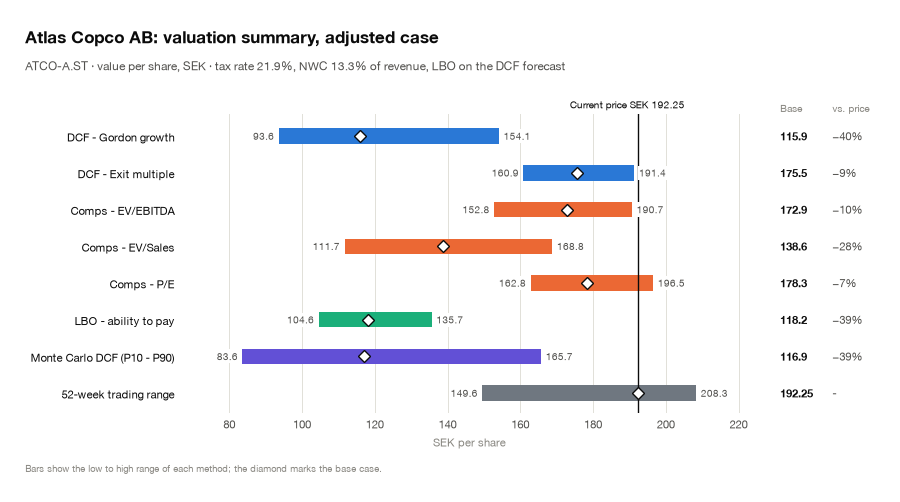

In [50]:
fig = viz.football_field(
    viz.report_valuations(adjusted),
    price,
    currency=adjusted.currency,
    title="Atlas Copco AB: valuation summary, adjusted case",
    subtitle=(
        f"{TICKER} · value per share, SEK · tax rate {tax_adjusted:.1%}, NWC {nwc_adjusted:.1%} "
        "of revenue, LBO on the DCF forecast"
    ),
)
show(fig, "football_field_adjusted")

Resultatet är nästan odramatiskt. Högre skatt sänker Gordon-värdet med ungefär 2 kr, lägre rörelsekapitalbindning höjer det med ungefär 2 kr, och tillsammans tar de ut varandra. LBO-värdet rör sig bara 0,3 kr: LBO:n räknar på samma prognos, och där tar de två ändringarna också ut varandra. Comps påverkas inte alls, eftersom de bara bygger på marknadsdata och senaste årets resultat.

Det är i sig en slutsats: de antaganden som går att pröva mot historiken är inte det som skiljer modellens värde från kursen.

## 11. Slutsats

Metoderna svarar på olika frågor, så jag väger dem olika.

* **Gordon-DCF (vikt 50 %)** är den enda metoden som inte lånar sin värdering från dagens börskurser. Den svarar på frågan vad kassaflödena är värda med ett avkastningskrav på 7,65 % och 2 % evig tillväxt.
* **Comps EV/EBITDA och P/E (25 % vardera)** svarar på vad Atlas Copco vore värt om bolaget prissattes som jämförelsebolagen i dag.
* **Exit-DCF (0 %)** är till 84 % samma sak som comps EV/EBITDA, eftersom slutvärdet använder samma peer-multipel. Att räkna med den vore att räkna comps två gånger.
* **EV/Sales (0 %)** bortser från marginalskillnaden mot jämförelsebolagen.
* **LBO (0 %)** är en räkneövning för ett bolag av den här storleken.
* **Monte Carlo (0 %)** är ingen egen metod utan osäkerheten kring Gordon-DCF:en.

In [51]:
values = {row.method.value: row for row in adjusted.valuations}
weights = {"dcf_gordon": 0.50, "comps_ev_ebitda": 0.25, "comps_pe": 0.25}
weighted = {
    level: sum(weight * getattr(values[key], level) for key, weight in weights.items())
    for level in ("low", "base", "high")
}
range_low = values["dcf_gordon"].base
range_high = values["comps_pe"].base
conclusion = pd.Series(
    {
        "range low: Gordon DCF base, adjusted case": range_low,
        "range high: comps P/E base": range_high,
        "weighted value (50% Gordon, 25% EV/EBITDA, 25% P/E)": weighted["base"],
        "weighted low": weighted["low"],
        "weighted high": weighted["high"],
        "current price": price,
        "price vs. range high": price / range_high - 1,
        "price vs. weighted value": price / weighted["base"] - 1,
    }
)
conclusion.to_frame("SEK per share / ratio")

,SEK per share / ratio
"range low: Gordon DCF base, adjusted case",115.90
range high: comps P/E base,178.33
"weighted value (50% Gordon, 25% EV/EBITDA, 25% P/E)",145.77
weighted low,125.71
weighted high,173.88
current price,192.25
price vs. range high,0.08
price vs. weighted value,0.32


**Värdeintervall 116 till 178 kr per aktie mot aktuell kurs 192,25 kr**, med tyngdpunkt kring 146 kr. Den nedre änden är vad kassaflödena motiverar med läroboksmässiga parametrar. Den övre är vad jämförelsebolagens prissättning motiverar. Kursen ligger 8 % över den övre änden och 32 % över tyngdpunkten.

Det betyder inte att aktien är "fel" prissatt. Det betyder att kursen förutsätter något som modellen inte antar: ett avkastningskrav närmare 6 än 7,65 %, en evig tillväxt närmare 3 än 2 %, eller någon blandning av de två. Hela gruppen av jämförelsebolag handlas på samma sätt, så frågan gäller marknadens syn på den här typen av bolag snarare än Atlas Copco ensamt. Modellen kan visa vad kursen kräver. Den kan inte avgöra om kravet är rimligt.

## 12. Universumkörningen (kräver nedladdad data)

Motorn kan köras på alla 687 svenska bolag: `python -m valuation_engine --all`. Det kräver att data först laddats ned till den lokala cachen (`python -m valuation_engine.data.download --all`, ungefär 18 minuter), och cachen ligger inte i git. Den här cellen läser därför batchens resultatfil om den finns och hoppar annars över avsnittet. Sökvägen är `output/universe_valuation.csv` eller miljövariabeln `UNIVERSE_CSV`.

In [52]:
universe_csv = Path(os.environ.get("UNIVERSE_CSV") or ROOT / "output" / "universe_valuation.csv")
universe = pd.read_csv(universe_csv) if universe_csv.is_file() else None
ratio_columns = {
    "DCF, Gordon growth": "dcf_gordon_base_to_price",
    "DCF, exit multiple": "dcf_exit_multiple_base_to_price",
    "Comps, EV/EBITDA": "comps_ev_ebitda_base_to_price",
    "Comps, EV/Sales": "comps_ev_sales_base_to_price",
    "Comps, P/E": "comps_pe_base_to_price",
    "LBO, ability to pay": "lbo_base_to_price",
    "Monte Carlo, median": "mc_p50_to_price",
}
if universe is None:
    print("No batch result found: this section is skipped. Run the batch first (see above).")
else:
    loaded = universe[universe["status"] != "no_data"]
    print(
        f"{len(universe)} companies, {len(loaded)} loaded;",
        universe["status"].value_counts().to_dict(),
    )
    print("methods per company:", universe["methods_count"].value_counts().sort_index().to_dict())
    distribution = pd.DataFrame(
        {
            label: {
                "companies": universe[column].notna().sum(),
                "share of loaded (%)": universe[column].notna().sum() / len(loaded) * 100,
                "P10": universe[column].quantile(0.10),
                "P25": universe[column].quantile(0.25),
                "median": universe[column].quantile(0.50),
                "P75": universe[column].quantile(0.75),
                "P90": universe[column].quantile(0.90),
                "within +/-25% of price (%)": universe[column].dropna().between(0.75, 1.25).mean()
                * 100,
                "negative values": (universe[column] < 0).sum(),
            }
            for label, column in ratio_columns.items()
        }
    ).T
    display(distribution)

687 companies, 680 loaded; {'partial': 386, 'ok': 294, 'no_data': 7}
methods per company: {0: 82, 1: 225, 2: 37, 3: 38, 4: 14, 5: 1, 6: 34, 7: 256}


,companies,share of loaded (%),P10,P25,median,P75,P90,within +/-25% of price (%),negative values
"DCF, Gordon growth",296.00,43.53,0.33,0.61,1.11,1.72,2.99,27.03,9.00
"DCF, exit multiple",296.00,43.53,0.60,0.90,1.26,1.77,3.09,31.76,3.00
"Comps, EV/EBITDA",374.00,55.00,0.36,0.66,0.99,1.55,2.27,33.16,0.00
"Comps, EV/Sales",525.00,77.21,0.25,0.51,0.93,1.67,3.00,22.48,0.00
"Comps, P/E",367.00,53.97,0.31,0.58,0.96,1.51,2.50,31.61,0.00
"LBO, ability to pay",316.00,46.47,0.30,0.57,0.81,1.15,1.87,32.59,0.00
"Monte Carlo, median",296.00,43.53,0.33,0.62,1.11,1.73,3.00,26.69,9.00


In [53]:
if universe is not None:
    buckets = pd.cut(
        universe["market_cap_sek"],
        [0, 1e9, 5e9, 20e9, np.inf],
        labels=["below 1 bn", "1 to 5 bn", "5 to 20 bn", "above 20 bn"],
    )
    by_size = universe.groupby(buckets, observed=True)[list(ratio_columns.values())].median()
    by_size.columns = list(ratio_columns)
    by_size.insert(0, "companies", universe.groupby(buckets, observed=True).size())
    by_size.insert(
        1,
        "with a DCF",
        universe.groupby(buckets, observed=True)["dcf_gordon_base_to_price"].count(),
    )
    display(by_size)
    reasons = universe["na_dcf"].dropna().str.split(":").str[0].value_counts()
    display(reasons.to_frame("companies without a DCF, by reason"))
    case_row = universe.set_index("ticker").loc[TICKER]
    print(
        f"{TICKER} in the batch (2,000 simulations): Gordon {case_row['dcf_gordon_base']:.1f}, "
        f"Monte Carlo P50 {case_row['mc_p50']:.1f}"
    )

,companies,with a DCF,"DCF, Gordon growth","DCF, exit multiple","Comps, EV/EBITDA","Comps, EV/Sales","Comps, P/E","LBO, ability to pay","Monte Carlo, median"
market_cap_sek,,,,,,,,,
below 1 bn,360,91,1.51,1.62,1.02,1.02,1.04,1.05,1.51
1 to 5 bn,124,66,1.22,1.26,1.00,0.78,0.81,0.82,1.23
5 to 20 bn,98,69,1.09,1.29,0.95,0.90,0.91,0.81,1.11
above 20 bn,98,70,0.76,1.02,0.95,0.92,0.94,0.66,0.76


,"companies without a DCF, by reason"
na_dcf,
negative EBITDA,154
financial sector,103
non-positive terminal cash flow,91
missing revenue,35
insufficient history,1


ATCO-A.ST in the batch (2,000 simulations): Gordon 115.8, Monte Carlo P50 116.5


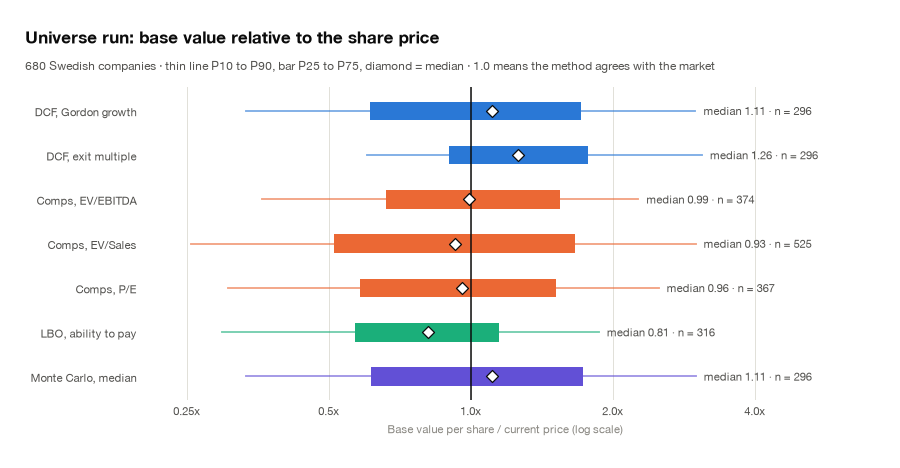

In [54]:
if universe is not None:
    colours = [
        style.BLUE,
        style.BLUE,
        style.ORANGE,
        style.ORANGE,
        style.ORANGE,
        style.AQUA,
        style.VIOLET,
    ]
    fig, ax = style.new_figure(
        "Universe run: base value relative to the share price",
        f"{len(loaded)} Swedish companies · thin line P10 to P90, bar P25 to P75, "
        "diamond = median · 1.0 means the method agrees with the market",
        figsize=(10.0, 5.2),
    )
    style.style_axes(ax, grid="x")
    labels = list(ratio_columns)
    for position, (label, colour) in enumerate(zip(labels, colours, strict=True)):
        row = distribution.loc[label]
        y = len(labels) - 1 - position
        ax.plot([row["P10"], row["P90"]], [y, y], color=colour, linewidth=1.5, alpha=0.6)
        ax.barh(y, row["P75"] - row["P25"], left=row["P25"], height=0.42, color=colour)
        ax.scatter(
            [row["median"]], [y], marker="D", s=46, color="white", edgecolor=style.INK, zorder=3
        )
        ax.text(
            row["P90"] * 1.04,
            y,
            f"median {row['median']:.2f} · n = {row['companies']:.0f}",
            va="center",
            fontsize=9,
            color=style.SECONDARY,
        )
    ax.axvline(1.0, color=style.INK, linewidth=1.2)
    ax.set_xscale("log")
    ax.set_xlim(0.2, 7.0)
    ax.set_xticks([0.25, 0.5, 1.0, 2.0, 4.0], ["0.25x", "0.5x", "1.0x", "2.0x", "4.0x"])
    ax.minorticks_off()
    ax.set_yticks(range(len(labels)), labels[::-1])
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Base value per share / current price (log scale)")
    show(style.finalize(fig), "universe_value_to_price")

Tre saker att ta med sig från universumkörningen (talen gäller körningen den 16 november 2026, den som redovisas i rapporten):

* **Täckningen är långt ifrån total.** Ungefär 44 % av de laddade bolagen får en DCF. Resten faller bort för att EBITDA är negativ, för att bolaget är en bank eller ett fastighetsbolag, eller för att marginalen inte räcker till ett positivt kassaflöde.
* **Medianen ligger nära kursen, men spridningen är enorm.** Bara ungefär vart fjärde bolag får ett DCF-värde inom 25 % från kursen. Att comps har median nära 1,0 är nästan en självklarhet: en relativvärdering centrerar sig kring marknaden.
* **Det finns ett storleksmönster.** DCF:en värderar småbolag högt och storbolag lågt relativt kursen. Atlas Copco följer alltså ett mönster som gäller hela gruppen av stora bolag.

## 13. Tabeller till rapporten och avstämning

Cellerna nedan skriver ut tabellerna i `docs/case_report.md` i svenskt format, direkt ur objekten ovan. Sist kommer en avstämning av de tal som nämns i löptexten här och i rapporten. Om motorn ändras och ett tal inte längre stämmer syns det där.

In [55]:
print("Tabell: historik (mdkr och procent)\n")
history_md = pd.DataFrame(
    {
        "Omsättning, mdkr": [sv(v / BN) for v in inc["revenue"]],
        "Tillväxt": [
            sv(v * 100, 1, " %") if np.isfinite(v) else "" for v in ratios["revenue growth"]
        ],
        "EBITDA-marginal": [sv(v * 100, 1, " %") for v in ratios["EBITDA margin"]],
        "Avskrivningar / omsättning": [sv(v * 100, 1, " %") for v in ratios["D&A / revenue"]],
        "Capex / omsättning": [sv(v * 100, 1, " %") for v in ratios["capex / revenue"]],
        "Rörelsekapital, smalt": [sv(v * 100, 1, " %") for v in ratios.iloc[:, 5]],
        "Rörelsekapital, brett": [sv(v * 100, 1, " %") for v in ratios.iloc[:, 6]],
        "Effektiv skatt": [sv(v * 100, 1, " %") for v in ratios["effective tax rate"]],
        "Fritt kassaflöde, mdkr": [sv(v / BN) for v in cf["free_cash_flow"]],
        "Förvärv, mdkr": [sv(v / BN) for v in raw_cf["Purchase Of Business"]],
    },
    index=pd.Index(statements.fiscal_years, name="Post"),
).T
md_table(history_md)

Tabell: historik (mdkr och procent)

|  | 2022 | 2023 | 2024 | 2025 |
|---|---:|---:|---:|---:|
| Omsättning, mdkr | 141,3 | 172,7 | 176,8 | 168,3 |
| Tillväxt |  | 22,2 % | 2,4 % | -4,8 % |
| EBITDA-marginal | 26,1 % | 26,1 % | 26,9 % | 26,2 % |
| Avskrivningar / omsättning | 4,5 % | 4,5 % | 5,0 % | 5,7 % |
| Capex / omsättning | 3,6 % | 3,2 % | 3,4 % | 3,7 % |
| Rörelsekapital, smalt | 26,9 % | 25,6 % | 26,0 % | 23,9 % |
| Rörelsekapital, brett | 13,8 % | 13,6 % | 13,5 % | 12,8 % |
| Effektiv skatt | 21,8 % | 23,0 % | 21,2 % | 21,5 % |
| Fritt kassaflöde, mdkr | 16,3 | 22,6 | 30,9 | 26,4 |
| Förvärv, mdkr | 10,6 | 4,3 | 7,4 | 11,6 |


In [56]:
def results_md(result):
    frame = valuation_frame(result).drop(index="52-week trading range")
    return pd.DataFrame(
        {
            "Låg": [sv(v) for v in frame["low"]],
            "Bas": [sv(v) for v in frame["base"]],
            "Hög": [sv(v) for v in frame["high"]],
            "Bas mot kurs": [sv((v / price - 1) * 100, 0, " %") for v in frame["base"]],
        },
        index=pd.Index(frame.index, name="Metod"),
    )


print("Tabell: resultat per metod, standardantaganden (kr per aktie)\n")
md_table(results_md(report))
print("\nTabell: resultat per metod, justerat fall (kr per aktie)\n")
md_table(results_md(adjusted))

Tabell: resultat per metod, standardantaganden (kr per aktie)

| Metod | Låg | Bas | Hög | Bas mot kurs |
|---|---:|---:|---:|---:|
| DCF - Gordon growth | 93,7 | 115,8 | 153,7 | -40 % |
| DCF - Exit multiple | 160,6 | 175,2 | 191,0 | -9 % |
| Comps - EV/EBITDA | 152,8 | 172,9 | 190,7 | -10 % |
| Comps - EV/Sales | 111,7 | 138,6 | 168,8 | -28 % |
| Comps - P/E | 162,8 | 178,3 | 196,5 | -7 % |
| LBO - ability to pay | 104,4 | 117,9 | 135,3 | -39 % |
| Monte Carlo DCF (P10 - P90) | 84,3 | 116,7 | 164,9 | -39 % |

Tabell: resultat per metod, justerat fall (kr per aktie)

| Metod | Låg | Bas | Hög | Bas mot kurs |
|---|---:|---:|---:|---:|
| DCF - Gordon growth | 93,6 | 115,9 | 154,1 | -40 % |
| DCF - Exit multiple | 160,9 | 175,5 | 191,4 | -9 % |
| Comps - EV/EBITDA | 152,8 | 172,9 | 190,7 | -10 % |
| Comps - EV/Sales | 111,7 | 138,6 | 168,8 | -28 % |
| Comps - P/E | 162,8 | 178,3 | 196,5 | -7 % |
| LBO - ability to pay | 104,6 | 118,2 | 135,7 | -39 % |
| Monte Carlo DCF (P10 - P90) | 83,

In [57]:
print("Tabell: vad kursen kräver\n")
implied_md = pd.DataFrame(
    {
        "Basfall": [
            sv(core["wacc"] * 100, 2, " %"),
            sv(core["terminal_growth"] * 100, 1, " %"),
            sv(base_margin * 100, 1, " %"),
            sv(base_growth.mean() * 100, 1, " %"),
            sv(core["exit_multiple"], 1, "x"),
        ],
        "Krävs för värde = kurs": [
            sv(implied_wacc * 100, 2, " %"),
            sv(implied_g * 100, 1, " %"),
            sv(implied_margin * 100, 1, " %"),
            sv((base_growth + implied_shift).mean() * 100, 1, " %"),
            sv(implied_exit, 1, "x"),
        ],
    },
    index=pd.Index(
        [
            "WACC",
            "Evig tillväxt",
            "EBITDA-marginal",
            "Snittillväxt år 1 till 5",
            "Exit-multipel (exit-metoden)",
        ],
        name="Drivare, en i taget",
    ),
)
md_table(implied_md)
print(
    "\nKombinationer av g och WACC som ger kursen:",
    "; ".join(
        f"g {sv(g * 100, 1, ' %')}: WACC {sv(value * 100, 2, ' %')}" for g, value in iso.items()
    ),
)
print("\nTabell: Monte Carlo\n")
md_table(
    pd.DataFrame(
        {
            label: [
                sv(row["P10"]),
                sv(row["P50"]),
                sv(row["P90"]),
                sv(row["share above price (%)"], 1, " %"),
            ]
            for label, row in mc_variants.iterrows()
        },
        index=pd.Index(["P10", "P50", "P90", "Andel över kursen"], name="Körning"),
    ).T
)
market_row = valuation_frame(report).loc["52-week trading range"]
print("\n52 veckor, veckostängningar:", sv(market_row["low"]), "till", sv(market_row["high"]))
adj_mc = adjusted.monte_carlo
print(
    "\njusterat fall, Monte Carlo:",
    sv(adj_mc.percentiles[10]),
    sv(adj_mc.percentiles[50]),
    sv(adj_mc.percentiles[90]),
    sv(adj_mc.prob_above_price * 100, 1, " %"),
)

Tabell: vad kursen kräver

| Drivare, en i taget | Basfall | Krävs för värde = kurs |
|---|---:|---:|
| WACC | 7,65 % | 5,39 % |
| Evig tillväxt | 2,0 % | 4,6 % |
| EBITDA-marginal | 26,4 % | 40,0 % |
| Snittillväxt år 1 till 5 | 4,0 % | 16,8 % |
| Exit-multipel (exit-metoden) | 19,4x | 21,7x |

Kombinationer av g och WACC som ger kursen: g 2,0 %: WACC 5,39 %; g 2,5 %: WACC 5,81 %; g 3,0 %: WACC 6,24 %; g 3,5 %: WACC 6,67 %; g 4,0 %: WACC 7,10 %; g 4,5 %: WACC 7,53 %

Tabell: Monte Carlo

|  | P10 | P50 | P90 | Andel över kursen |
|---|---:|---:|---:|---:|
| default: 10,000 draws, seed 42 | 84,3 | 116,7 | 164,9 | 3,3 % |
| 100,000 draws, seed 7 | 84,0 | 116,3 | 165,2 | 3,3 % |
| growth std 3 pp instead of 5 pp | 90,0 | 116,6 | 155,4 | 1,7 % |

52 veckor, veckostängningar: 149,6 till 208,3

justerat fall, Monte Carlo: 83,6 116,9 165,7 3,4 %


In [58]:
if universe is not None:
    print("Tabell: universum, basvärde delat med kurs\n")
    md_table(
        pd.DataFrame(
            {
                "Bolag": [sv(v, 0) for v in distribution["companies"]],
                "Andel av laddade": [sv(v, 0, " %") for v in distribution["share of loaded (%)"]],
                "P10": [sv(v, 2) for v in distribution["P10"]],
                "P25": [sv(v, 2) for v in distribution["P25"]],
                "Median": [sv(v, 2) for v in distribution["median"]],
                "P75": [sv(v, 2) for v in distribution["P75"]],
                "P90": [sv(v, 2) for v in distribution["P90"]],
                "Inom 25 % från kursen": [
                    sv(v, 0, " %") for v in distribution["within +/-25% of price (%)"]
                ],
            },
            index=pd.Index(distribution.index, name="Metod"),
        )
    )
    print("\nTabell: median av basvärde delat med kurs, per börsvärde\n")
    size_md = by_size[
        [
            "companies",
            "with a DCF",
            "DCF, Gordon growth",
            "Comps, EV/EBITDA",
            "Comps, P/E",
            "LBO, ability to pay",
        ]
    ]
    md_table(
        pd.DataFrame(
            {
                "Bolag": [sv(v, 0) for v in size_md["companies"]],
                "Med DCF": [sv(v, 0) for v in size_md["with a DCF"]],
                "DCF Gordon": [sv(v, 2) for v in size_md["DCF, Gordon growth"]],
                "Comps EV/EBITDA": [sv(v, 2) for v in size_md["Comps, EV/EBITDA"]],
                "Comps P/E": [sv(v, 2) for v in size_md["Comps, P/E"]],
                "LBO": [sv(v, 2) for v in size_md["LBO, ability to pay"]],
            },
            index=pd.Index(
                ["under 1 mdkr", "1 till 5 mdkr", "5 till 20 mdkr", "över 20 mdkr"],
                name="Börsvärde",
            ),
        )
    )

Tabell: universum, basvärde delat med kurs

| Metod | Bolag | Andel av laddade | P10 | P25 | Median | P75 | P90 | Inom 25 % från kursen |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| DCF, Gordon growth | 296 | 44 % | 0,33 | 0,61 | 1,11 | 1,72 | 2,99 | 27 % |
| DCF, exit multiple | 296 | 44 % | 0,60 | 0,90 | 1,26 | 1,77 | 3,09 | 32 % |
| Comps, EV/EBITDA | 374 | 55 % | 0,36 | 0,66 | 0,99 | 1,55 | 2,27 | 33 % |
| Comps, EV/Sales | 525 | 77 % | 0,25 | 0,51 | 0,93 | 1,67 | 3,00 | 22 % |
| Comps, P/E | 367 | 54 % | 0,31 | 0,58 | 0,96 | 1,51 | 2,50 | 32 % |
| LBO, ability to pay | 316 | 46 % | 0,30 | 0,57 | 0,81 | 1,15 | 1,87 | 33 % |
| Monte Carlo, median | 296 | 44 % | 0,33 | 0,62 | 1,11 | 1,73 | 3,00 | 27 % |

Tabell: median av basvärde delat med kurs, per börsvärde

| Börsvärde | Bolag | Med DCF | DCF Gordon | Comps EV/EBITDA | Comps P/E | LBO |
|---|---:|---:|---:|---:|---:|---:|
| under 1 mdkr | 360 | 91 | 1,51 | 1,02 | 1,04 | 1,05 |
| 1 till 5 mdkr | 124 | 66 | 1,22 | 1,00 | 0,81 |

In [59]:
# Numbers quoted in the text of this notebook and of docs/case_report.md.
quoted = [
    ("price", price, 192.25, 2),
    ("DCF Gordon, default", dcf.value_per_share_gordon, 115.8, 1),
    ("DCF exit, default", dcf.value_per_share_exit, 175.2, 1),
    ("comps EV/EBITDA base", values["comps_ev_ebitda"].base, 172.9, 1),
    ("comps P/E base", values["comps_pe"].base, 178.3, 1),
    ("LBO base, default", lbo.ability_to_pay[0.20], 117.9, 1),
    ("Monte Carlo P50, default", mc.percentiles[50], 116.7, 1),
    ("WACC (%)", dcf.wacc * 100, 7.65, 2),
    ("exit multiple", dcf.exit_multiple, 19.4, 1),
    ("implied WACC (%)", implied_wacc * 100, 5.39, 2),
    ("implied g (%)", implied_g * 100, 4.6, 1),
    ("DCF Gordon, adjusted", adjusted.dcf.value_per_share_gordon, 115.9, 1),
    ("LBO base, adjusted", adjusted.lbo.ability_to_pay[0.20], 118.2, 1),
    ("weighted value", weighted["base"], 145.8, 1),
]
check = pd.DataFrame(quoted, columns=["number", "computed", "quoted", "decimals"])
check["agrees"] = [
    sv(c, d) == sv(q, d)
    for c, q, d in zip(check["computed"], check["quoted"], check["decimals"], strict=True)
]
print("all quoted numbers agree with this run:", bool(check["agrees"].all()))
check.drop(columns="decimals")

all quoted numbers agree with this run: True


,number,computed,quoted,agrees
0,price,192.25,192.25,True
1,"DCF Gordon, default",115.85,115.80,True
2,"DCF exit, default",175.23,175.20,True
3,comps EV/EBITDA base,172.93,172.90,True
4,comps P/E base,178.33,178.30,True
5,"LBO base, default",117.93,117.90,True
6,"Monte Carlo P50, default",116.74,116.70,True
7,WACC (%),7.65,7.65,True
8,exit multiple,19.43,19.40,True
9,implied WACC (%),5.39,5.39,True
